# Avance 1 — Análisis exploratorio de datos (EDA) y preprocesamiento
**Equipo 11 · Corpus sintético piloto para generación de TDD**

Este notebook explora una **muestra piloto** con la misma estructura que se usará después en el proyecto (generación de documentos TDD a partir de sesiones técnicas). Aún no se evalúan modelos ni agentes: el objetivo es entender el corpus, revisar su calidad y dejar una estructura de datos reutilizable cuando existan sesiones reales o desensibilizadas.

La muestra contiene **6 sesiones, 30 segmentos de transcripción, 30 preguntas de evaluación y 6 documentos RAG**. Es deliberadamente pequeña: las estadísticas son **descriptivas** y no sustituyen al corpus final.

**Estructura del notebook**

| # | Sección | Objetivo de la rúbrica |
|---|---|---|
| 1 | Carga de datos y procedencia | Archivos de entrada, rutas, huellas (SHA-256) |
| 2 | Estructura de los datos | Forma, tipos, estadísticas, frecuencias, faltantes, cardinalidad |
| 3 | Calidad de los datos | Detección de problemas (sin modificar nada aún) |
| 4 | Análisis univariante | Histogramas, boxplots, barras, asimetría, atípicos, dimensión temporal |
| 5 | Preprocesamiento | Faltantes, atípicos, duplicados, alta cardinalidad: ejecución, justificación y **pruebas de calidad** (con caso de fallo) |
| 6 | Análisis bi/multivariante | Correlaciones (tabla + gráfico), asociación entre categóricas, balance de clases |
| 7 | Selección de características | Reducción de dimensionalidad |
| 8 | Evaluación del sistema: estado y pendientes | Qué falta para validar y probar (no se presenta como resultado) |
| 9 | Exportación | Resultados en `output/` |
| 10 | Conclusiones | Respuestas a las preguntas del EDA |

*Nota de orden:* el análisis bi/multivariante se hace **después** del preprocesamiento para que los coeficientes no estén distorsionados por registros inválidos (por ejemplo, un segmento con duración negativa). Los datos de entrada están en `data/` y no se modifican.

## 1. Carga de datos

Cada CSV representa una parte distinta del corpus. **Hallazgo de calidad:** los archivos no comparten codificación: `transcript_segments_raw.csv` está en `cp1252` y los otros tres en `utf-8`. Forzar una sola codificación (por ejemplo `latin-1` para todos) corrompe los acentos en los archivos UTF-8 (`sintÃ©tica`, `deberÃ¡`). Por eso la función de carga prueba `utf-8` primero y, solo si falla, usa `cp1252`.

In [2]:
from pathlib import Path
import re
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr, chi2_contingency, kruskal
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

# Rutas relativas: el proyecto se ejecuta desde su carpeta, sin depender de rutas de una computadora.
DATA = Path("data") if Path("data").exists() else Path(".")
OUTPUT = Path("output")
OUTPUT.mkdir(exist_ok=True)


def read_csv_robust(path):
    """Lee un CSV probando utf-8 y luego cp1252; informa cuál funcionó."""
    for enc in ("utf-8", "cp1252"):
        try:
            df = pd.read_csv(path, encoding=enc)
            print(f"{path.name:32s} -> encoding = {enc}")
            return df
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No se pudo decodificar {path}")


def wrap_labels(ax, width=24, axis="y"):
    """Parte etiquetas largas en varias líneas para que no se corten en las gráficas."""
    if axis == "y":
        ax.set_yticks(ax.get_yticks())
        ax.set_yticklabels([textwrap.fill(t.get_text(), width) for t in ax.get_yticklabels()])
    else:
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels([textwrap.fill(t.get_text(), width) for t in ax.get_xticklabels()])


def int_ticks(*axes, axis="y"):
    """Fuerza marcas enteras en ejes de conteo (no tiene sentido 3.5 documentos)."""
    from matplotlib.ticker import MaxNLocator
    for a in axes:
        (a.yaxis if axis == "y" else a.xaxis).set_major_locator(MaxNLocator(integer=True))


REQUIRED = ["sessions_synthetic.csv", "transcript_segments_raw.csv",
            "gold_standard_synthetic.csv", "rag_documents_synthetic.csv"]
missing_files = [f for f in REQUIRED if not (DATA / f).exists()]
if missing_files:
    raise FileNotFoundError(
        f"Faltan archivos de entrada en '{DATA.resolve()}': {missing_files}. "
        "Coloca los 4 CSV en la carpeta data/ junto al notebook."
    )

sessions = read_csv_robust(DATA / "sessions_synthetic.csv")
segments = read_csv_robust(DATA / "transcript_segments_raw.csv")
gold = read_csv_robust(DATA / "gold_standard_synthetic.csv")
rag_docs = read_csv_robust(DATA / "rag_documents_synthetic.csv")

print()
print("Sesiones:", len(sessions))
print("Segmentos:", len(segments))
print("Preguntas de evaluación:", len(gold))
print("Documentos RAG:", len(rag_docs))

sessions_synthetic.csv           -> encoding = utf-8
transcript_segments_raw.csv      -> encoding = cp1252
gold_standard_synthetic.csv      -> encoding = utf-8
rag_documents_synthetic.csv      -> encoding = utf-8

Sesiones: 6
Segmentos: 30
Preguntas de evaluación: 30
Documentos RAG: 6


### 1.1 Procedencia y huella de los archivos de entrada

Para comprobar que las tablas y figuras corresponden a estos archivos y a esta versión del código se registran la ruta de carga, el tamaño y la huella **SHA-256** de cada CSV. Si el repositorio contiene archivos distintos, las huellas no coincidirán.

**Procedencia:** los cuatro CSV son **sintéticos y diseñados manualmente** por el equipo para el piloto (no provienen de reuniones reales). *Pendiente de completar por el equipo: autor o script generador, fecha de creación y enlace al commit donde se versionó `data/`.*

In [3]:
import hashlib, platform

prov = []
for f in REQUIRED:
    p = DATA / f
    prov.append([f, str(p), p.stat().st_size, hashlib.sha256(p.read_bytes()).hexdigest()[:16]])
display(pd.DataFrame(prov, columns=["archivo", "ruta_de_carga", "bytes", "sha256 (16 primeros)"]))
print("Entorno -> Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)

,archivo,ruta_de_carga,bytes,sha256 (16 primeros)
0,sessions_synthetic.csv,sessions_synthetic.csv,429,d11251c8210f7066
1,transcript_segments_raw.csv,transcript_segments_raw.csv,4530,1243e8b282c2303c
2,gold_standard_synthetic.csv,gold_standard_synthetic.csv,7106,467ccbcbdd3f329f
3,rag_documents_synthetic.csv,rag_documents_synthetic.csv,318,006fd66f45ea8eee


Entorno -> Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3


## 2. Estructura de los datos

Se describe la forma y los tipos de cada tabla, las estadísticas resumidas, la frecuencia de las clases de cada variable categórica, los valores faltantes y la cardinalidad.

### 2.1 Forma y tipos de datos

In [4]:
tablas = {"sessions": sessions, "segments": segments, "gold": gold, "rag_docs": rag_docs}

resumen = pd.DataFrame({
    nombre: {"filas": df.shape[0], "columnas": df.shape[1], "celdas_faltantes": int(df.isna().sum().sum())}
    for nombre, df in tablas.items()
}).T
display(resumen)

for nombre, df in tablas.items():
    print(f"\n{'=' * 70}\n{nombre.upper()}  shape = {df.shape}\n{'=' * 70}")
    df.info()

,filas,columnas,celdas_faltantes
sessions,6,8,0
segments,30,9,2
gold,30,10,2
rag_docs,6,6,5



SESSIONS  shape = (6, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   session_id      6 non-null      object
 1   project_phase   6 non-null      object
 2   duration_min    6 non-null      int64 
 3   num_speakers    6 non-null      int64 
 4   video_format    6 non-null      object
 5   has_audio       6 non-null      bool  
 6   has_transcript  6 non-null      bool  
 7   dataset_split   6 non-null      object
dtypes: bool(2), int64(2), object(4)
memory usage: 432.0+ bytes

SEGMENTS  shape = (30, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   session_id            30 non-null     object
 1   segment_id            30 non-null     object
 2   start_sec             30 non-null   

### 2.2 Estadísticas descriptivas de todas las variables

In [5]:
# describe(include="all") cubre numéricas (media, desviación, cuartiles) y categóricas (únicos, moda, frecuencia).
for nombre, df in tablas.items():
    print(f"\n--- {nombre} ---")
    display(df.describe(include="all").T.round(2))


--- sessions ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
session_id,6,6,S01_DISCOVERY,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
project_phase,6,6,Discovery,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration_min,6.0,NaN,NaN,NaN,34.833333,3.710346,30.0,32.5,34.5,37.25,40.0
num_speakers,6.0,NaN,NaN,NaN,3.5,0.547723,3.0,3.0,3.5,4.0,4.0
video_format,6,2,MP4,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_audio,6,1,True,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_transcript,6,2,True,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dataset_split,6,3,development,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- segments ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
session_id,30,5,S01_DISCOVERY,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment_id,30,30,SEG001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_sec,30.0,NaN,NaN,NaN,620.6,505.635251,15.0,211.25,495.0,980.0,1750.0
end_sec,30.0,NaN,NaN,NaN,639.6,505.541676,28.0,231.25,516.5,1000.0,1770.0
speaker,29,7,Ana_PM,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
speaker_role,30,6,pm,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text_raw,29,28,Se revisará manualmente una muestra de respuestas para comparar co...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expected_category,30,5,scope_next_step,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_visual_reference,30,2,False,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- gold ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
question_id,30,30,Q001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
session_id,30,5,S02_ARCH,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,30,5,Requisitos funcionales,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
question,30,30,Pregunta sintética 1 sobre requisitos funcionales.,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expected_answer,30,25,La solución debe conservar trazabilidad de cada requisito hasta su...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
evidence_type,30,1,session,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
evidence_reference,30,25,S02_ARCH#SEG009,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp_start_sec,30.0,NaN,NaN,NaN,567.0,501.947243,15.0,211.25,420.0,820.0,1750.0
timestamp_end_sec,30.0,NaN,NaN,NaN,586.633333,502.622329,28.0,231.25,441.0,841.5,1770.0
reviewer,28,3,reviewer_2,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- rag_docs ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
doc_id,6,6,RAG01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
document_type,6,6,TDD Template,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
file_format,6,3,PDF,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
word_count,6.0,NaN,NaN,NaN,1816.666667,1293.702696,0.0,975.0,2000.0,2800.0,3200.0
status,6,3,ready,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duplicate_of,1,1,RAG03,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2.3 Frecuencia de las clases (variables categóricas)

Una sola tabla larga con la frecuencia absoluta y relativa de cada clase, para todas las variables categóricas del corpus.

In [6]:
cat_cols = {
    "sessions": ["project_phase", "video_format", "has_audio", "has_transcript", "dataset_split"],
    "segments": ["session_id", "speaker", "speaker_role", "expected_category", "has_visual_reference"],
    "gold": ["session_id", "category", "evidence_type", "reviewer"],
    "rag_docs": ["document_type", "file_format", "status", "duplicate_of"],
}

freq_rows = []
for tabla, cols in cat_cols.items():
    df = tablas[tabla]
    for c in cols:
        vc = df[c].value_counts(dropna=False)
        for clase, n in vc.items():
            freq_rows.append([tabla, c, "(faltante)" if pd.isna(clase) else clase, int(n), round(100 * n / len(df), 1)])

freq_table = pd.DataFrame(freq_rows, columns=["tabla", "variable", "clase", "n", "porcentaje"])
display(freq_table)

,tabla,variable,clase,n,porcentaje
0,sessions,project_phase,Discovery,1,16.7
1,sessions,project_phase,Architecture,1,16.7
2,sessions,project_phase,Security,1,16.7
3,sessions,project_phase,Implementation,1,16.7
4,sessions,project_phase,Review / Next Steps,1,16.7
...,...,...,...,...,...
64,rag_docs,status,ready,4,66.7
65,rag_docs,status,empty,1,16.7
66,rag_docs,status,duplicate,1,16.7
67,rag_docs,duplicate_of,(faltante),5,83.3


### 2.4 Valores faltantes y patrones de ausencia

Primero se cuantifican los faltantes de las cuatro tablas y después se visualiza **dónde** ocurren, para buscar patrones.

Nota: en `rag_docs`, `duplicate_of` está vacío en 5 de 6 filas **por diseño** (solo aplica a documentos duplicados). Es un faltante estructural, no un error.

Columnas con valores faltantes:


faltantes  porcentaje
segments speaker               1         3.3
         text_raw              1         3.3
gold     reviewer              2         6.7
rag_docs duplicate_of          5        83.3

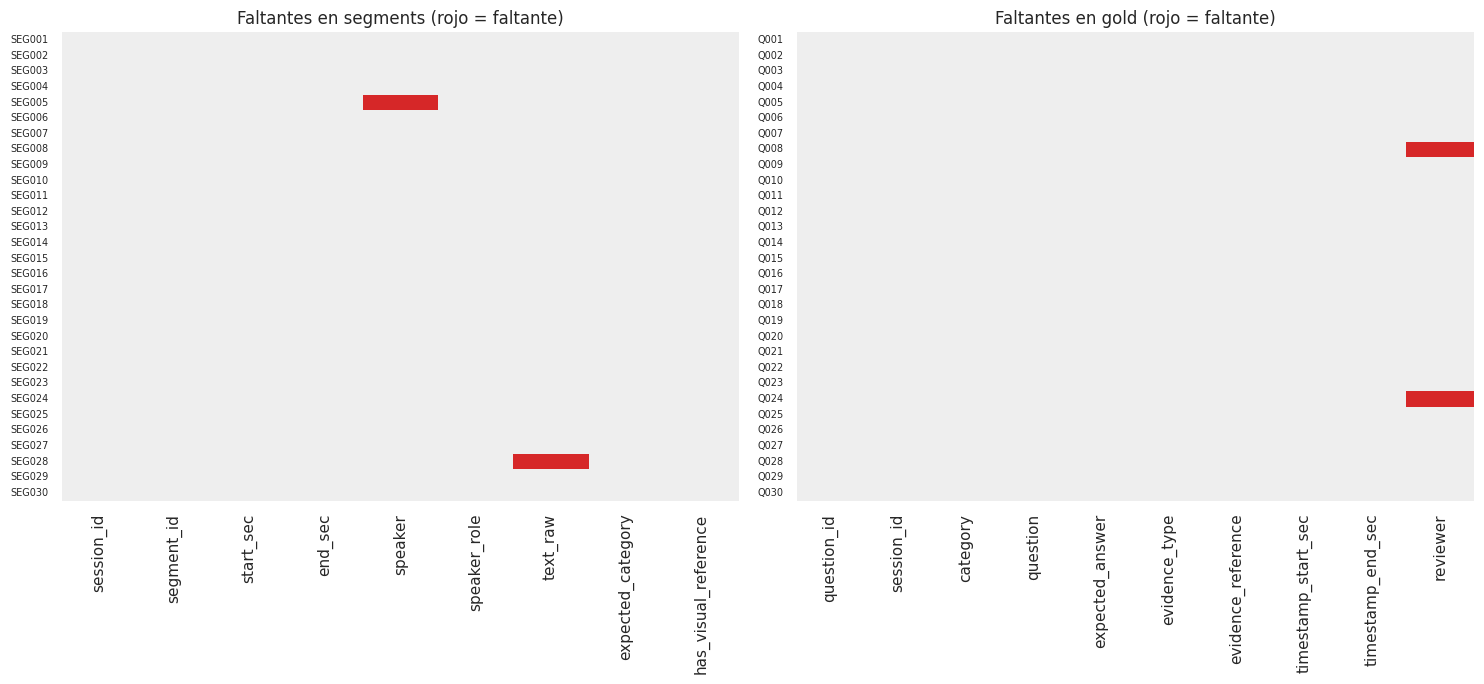

Segmentos con algún faltante:


,session_id,segment_id,speaker,speaker_role,text_raw
4,S01_DISCOVERY,SEG005,NaN,client,El cliente también requiere descargar el resultado en PDF.
27,S05_REVIEW,SEG028,Miguel_Consultant,consultant,NaN


Preguntas del gold con algún faltante:


,question_id,session_id,category,reviewer
7,Q008,S02_ARCH,Requisitos no funcionales e infraestructura,NaN
23,Q024,S02_ARCH,Riesgos y dependencias,NaN


In [7]:
faltantes = pd.concat({n: df.isna().sum() for n, df in tablas.items()}).rename("faltantes").to_frame()
faltantes["porcentaje"] = (
    faltantes["faltantes"] / [len(tablas[t]) for t, _ in faltantes.index] * 100
).round(1)
print("Columnas con valores faltantes:")
display(faltantes[faltantes["faltantes"] > 0])

# Mapa de ausencias: cada fila es un registro; las celdas rojas son valores faltantes.
from matplotlib.colors import ListedColormap
cmap_missing = ListedColormap(["#eeeeee", "#d62728"])

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
sns.heatmap(segments.isna(), cbar=False, cmap=cmap_missing, yticklabels=segments["segment_id"], ax=axes[0])
axes[0].set_title("Faltantes en segments (rojo = faltante)")
axes[0].tick_params(axis="y", labelsize=7)
sns.heatmap(gold.isna(), cbar=False, cmap=cmap_missing, yticklabels=gold["question_id"], ax=axes[1])
axes[1].set_title("Faltantes en gold (rojo = faltante)")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

print("Segmentos con algún faltante:")
display(segments[segments[["speaker", "text_raw"]].isna().any(axis=1)][["session_id", "segment_id", "speaker", "speaker_role", "text_raw"]])
print("Preguntas del gold con algún faltante:")
display(gold[gold.isna().any(axis=1)][["question_id", "session_id", "category", "reviewer"]])

**Lectura del patrón de ausencia.** Los faltantes son pocos, puntuales y **no coinciden en el mismo registro**: el speaker faltante (S01) y el texto faltante (S05) están en sesiones y segmentos distintos, pero en `gold` los dos `reviewer` faltantes (Q008 y Q024) corresponden **ambos a la sesión S02**, un posible indicio de que la revisión de esa sesión quedó incompleta. Con solo 2 casos no puede probarse formalmente (MCAR/MAR), así que se tratan caso por caso en la sección 5.

### 2.5 Cardinalidad de las variables

Sirve para distinguir **identificadores** (únicos por fila, no son variables explicativas) de **categorías reutilizables** y para detectar **alta cardinalidad** (muchas categorías, típicamente un problema al codificar). Criterio: constante si tiene 1 valor; identificador si es único por fila; *alta cardinalidad* si más de la mitad de las filas tienen un valor distinto; baja/moderada en otro caso.

In [8]:
def tipo_cardinalidad(n_unique, n_rows, rol):
    if rol == "id":
        return "identificador / clave"
    if n_unique <= 1:
        return "constante"
    if n_unique == n_rows:
        return "única por fila (muestra mínima)"
    if n_unique / n_rows > 0.5:
        return "ALTA cardinalidad"
    return "baja / moderada"


# rol: "id" = identificador o referencia (clave de trazabilidad); "cat" = variable categórica
card_cols = {
    "sessions": {"session_id": "id", "project_phase": "cat", "video_format": "cat", "has_audio": "cat", "has_transcript": "cat", "dataset_split": "cat"},
    "segments": {"session_id": "id", "segment_id": "id", "speaker": "cat", "speaker_role": "cat", "expected_category": "cat"},
    "gold": {"question_id": "id", "session_id": "id", "category": "cat", "evidence_reference": "id", "reviewer": "cat"},
    "rag_docs": {"doc_id": "id", "document_type": "cat", "file_format": "cat", "status": "cat"},
}

card_rows = []
for tabla, cols in card_cols.items():
    df = tablas[tabla]
    for c, rol in cols.items():
        n_u = int(df[c].nunique(dropna=True))
        card_rows.append([tabla, c, rol, n_u, round(n_u / len(df), 2), tipo_cardinalidad(n_u, len(df), rol)])

cardinality = pd.DataFrame(card_rows, columns=["tabla", "columna", "rol", "valores_unicos", "proporcion_unica", "tipo"])
display(cardinality)

print("Variables con ALTA cardinalidad:", cardinality.loc[cardinality["tipo"] == "ALTA cardinalidad", "columna"].tolist() or "ninguna")
print("Variables constantes:", cardinality.loc[cardinality["tipo"] == "constante", ["tabla", "columna"]].values.tolist())
print("Únicas por fila solo por el tamaño de la muestra (6 filas):", cardinality.loc[cardinality["tipo"].str.startswith("única"), ["tabla", "columna"]].values.tolist())
print(f"segments.session_id tiene {segments['session_id'].nunique()} valores frente a {sessions['session_id'].nunique()} sesiones: la sesión sin transcripción no aporta segmentos.")

,tabla,columna,rol,valores_unicos,proporcion_unica,tipo
0,sessions,session_id,id,6,1.00,identificador / clave
1,sessions,project_phase,cat,6,1.00,única por fila (muestra mínima)
2,sessions,video_format,cat,2,0.33,baja / moderada
3,sessions,has_audio,cat,1,0.17,constante
4,sessions,has_transcript,cat,2,0.33,baja / moderada
5,sessions,dataset_split,cat,3,0.50,baja / moderada
6,segments,session_id,id,5,0.17,identificador / clave
7,segments,segment_id,id,30,1.00,identificador / clave
8,segments,speaker,cat,7,0.23,baja / moderada
9,segments,speaker_role,cat,6,0.20,baja / moderada


Variables con ALTA cardinalidad: ninguna
Variables constantes: [['sessions', 'has_audio']]
Únicas por fila solo por el tamaño de la muestra (6 filas): [['sessions', 'project_phase'], ['rag_docs', 'document_type']]
segments.session_id tiene 5 valores frente a 6 sesiones: la sesión sin transcripción no aporta segmentos.


## 3. Calidad de los datos

Primero **se crean banderas de calidad sin modificar los datos**: se identifican los problemas y después (sección 5) se decide cómo tratarlos.

La función `clean_text` elimina etiquetas HTML y normaliza espacios. También incluye el manejo de formato **WebVTT** (timestamps y etiquetas `<v Speaker>`) que usaban los primeros borradores del equipo: no afecta a los CSV actuales, pero deja el pipeline listo para transcripciones reales.

In [9]:
def clean_text(text):
    """Limpia markup de formato y normaliza espacios; devuelve '' si el texto falta."""
    if pd.isna(text):
        return ""
    text = str(text)
    # 1) Formato WebVTT (no presente en los CSV piloto; útil para sesiones reales)
    text = re.sub(r"\d{2}:\d{2}:\d{2}\.\d{3} --> \d{2}:\d{2}:\d{2}\.\d{3}\n*", "", text)
    text = re.sub(r"<v ([^>]+)>(.*?)</v>", r"\1: \2", text)
    # 2) Etiquetas HTML (<i>, <b>, <br>, ...)
    text = re.sub(r"<br\s*/?>", " ", text)   # salto de línea HTML: separa palabras
    text = re.sub(r"<[^>]+>", "", text)       # etiquetas en línea (<i>, <b>, ...): se quitan sin dejar espacio
    # 3) Espacios y saltos de línea
    return re.sub(r"\s+", " ", text).strip()


# Prueba rápida con un fragmento WebVTT de ejemplo
vtt_demo = ("00:00:01.500 --> 00:00:10.000\n<v Juan_PM>Hola a todos, bienvenidos al Kickoff.</v>\n"
            "00:00:10.500 --> 00:00:20.000\n<v Juan_PM>Soy el <i>Project Manager</i>.</v>")
print("VTT limpio:", clean_text(vtt_demo))

VTT limpio: Juan_PM: Hola a todos, bienvenidos al Kickoff. Juan_PM: Soy el Project Manager.


Resumen de calidad:


,tabla,problema,casos_detectados
0,segments,Texto faltante,1
1,segments,Speaker faltante,1
2,segments,Timestamp inválido (fin <= inicio),1
3,segments,Segmento duplicado (copia redundante),1
4,segments,Markup HTML,1
5,sessions,Sesión sin transcripción,1
6,gold,Respuesta esperada faltante,0
7,gold,Evidencia faltante,0
8,gold,Revisor faltante,2
9,gold,Markup HTML en pregunta/respuesta,1


Nota: el grupo duplicado de segmentos abarca 2 filas; solo 1 es redundante (se conserva la primera).

Problemas detectados por sesión (S06 no tiene segmentos):


,segmentos,q_missing_text,q_missing_speaker,q_invalid_timestamp,q_duplicate,q_html_markup
session_id,,,,,,
S01_DISCOVERY,6,0,1,0,0,0
S02_ARCH,6,0,0,0,0,1
S03_SECURITY,6,0,0,1,0,0
S04_IMPL,6,0,0,0,0,0
S05_REVIEW,6,1,0,0,1,0
S06_HANDOVER,0,0,0,0,0,0


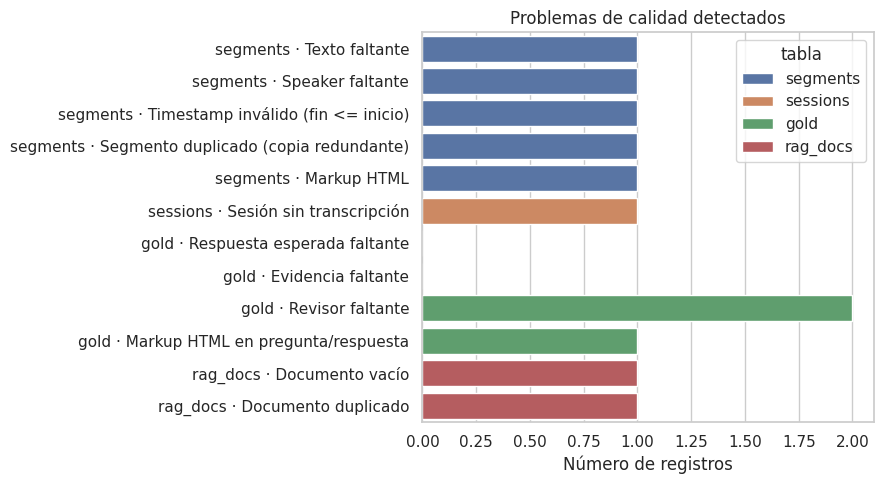

In [10]:
# ---------------- Banderas de calidad: segmentos ----------------
segments["q_missing_text"] = segments["text_raw"].isna() | segments["text_raw"].fillna("").str.strip().eq("")
segments["q_missing_speaker"] = segments["speaker"].isna()
segments["q_invalid_timestamp"] = (
    segments["start_sec"].isna() | segments["end_sec"].isna() | (segments["end_sec"] <= segments["start_sec"])
)

# Duplicados: se ignoran mayúsculas, espacios y etiquetas HTML.
segments["text_for_duplicate_check"] = segments["text_raw"].apply(clean_text).str.lower()
dup_keys = ["session_id", "text_for_duplicate_check"]
segments["q_duplicate_group"] = segments.duplicated(dup_keys, keep=False) & ~segments["q_missing_text"]  # todas las filas del grupo
segments["q_duplicate"] = segments.duplicated(dup_keys, keep="first") & ~segments["q_missing_text"]      # solo la copia redundante

segments["q_html_markup"] = segments["text_raw"].fillna("").str.contains(r"<[^>]+>", regex=True)

# Variables derivadas (no destructivas). Si falta el texto, la longitud es NaN y no 0: no es una medición real.
segments["text_clean"] = segments["text_raw"].apply(clean_text)
segments["speaker_clean"] = segments["speaker"].fillna("UNKNOWN")
segments["segment_duration_sec"] = segments["end_sec"] - segments["start_sec"]
segments["word_count"] = segments["text_clean"].str.split().str.len().where(~segments["q_missing_text"])
# Aproximación de tokens (~4 caracteres por token); no sustituye al tokenizer del modelo final.
segments["estimated_tokens"] = np.ceil(segments["text_clean"].str.len() / 4).where(~segments["q_missing_text"])

# ---------------- Banderas de calidad: gold y RAG ----------------
def vacio(s):
    return s.isna() | s.fillna("").astype(str).str.strip().eq("")

gold["q_missing_answer"] = vacio(gold["expected_answer"])
gold["q_missing_evidence"] = vacio(gold["evidence_reference"])
gold["q_missing_reviewer"] = vacio(gold["reviewer"])
gold["q_html_markup"] = (gold["question"].fillna("").str.contains(r"<[^>]+>", regex=True)
                         | gold["expected_answer"].fillna("").str.contains(r"<[^>]+>", regex=True))

rag_docs["q_empty"] = rag_docs["word_count"] == 0
rag_docs["q_duplicate"] = rag_docs["status"] == "duplicate"

# ---------------- Reporte de calidad consolidado ----------------
sessions_sin_transcripcion = ~sessions["has_transcript"]
quality_report = pd.DataFrame([
    ["segments", "Texto faltante", int(segments["q_missing_text"].sum())],
    ["segments", "Speaker faltante", int(segments["q_missing_speaker"].sum())],
    ["segments", "Timestamp inválido (fin <= inicio)", int(segments["q_invalid_timestamp"].sum())],
    ["segments", "Segmento duplicado (copia redundante)", int(segments["q_duplicate"].sum())],
    ["segments", "Markup HTML", int(segments["q_html_markup"].sum())],
    ["sessions", "Sesión sin transcripción", int(sessions_sin_transcripcion.sum())],
    ["gold", "Respuesta esperada faltante", int(gold["q_missing_answer"].sum())],
    ["gold", "Evidencia faltante", int(gold["q_missing_evidence"].sum())],
    ["gold", "Revisor faltante", int(gold["q_missing_reviewer"].sum())],
    ["gold", "Markup HTML en pregunta/respuesta", int(gold["q_html_markup"].sum())],
    ["rag_docs", "Documento vacío", int(rag_docs["q_empty"].sum())],
    ["rag_docs", "Documento duplicado", int(rag_docs["q_duplicate"].sum())],
], columns=["tabla", "problema", "casos_detectados"])

print("Resumen de calidad:")
display(quality_report)
print(f"Nota: el grupo duplicado de segmentos abarca {int(segments['q_duplicate_group'].sum())} filas; solo 1 es redundante (se conserva la primera).")

# ¿Los problemas están concentrados en una sesión o repartidos?
flag_cols = ["q_missing_text", "q_missing_speaker", "q_invalid_timestamp", "q_duplicate", "q_html_markup"]
quality_by_session = segments.groupby("session_id")[flag_cols].sum()
quality_by_session.insert(0, "segmentos", segments.groupby("session_id").size())
quality_by_session = quality_by_session.reindex(sessions["session_id"]).fillna(0).astype(int)
print("\nProblemas detectados por sesión (S06 no tiene segmentos):")
display(quality_by_session)

fig, ax = plt.subplots(figsize=(9, 5))
plot_q = quality_report.assign(etiqueta=quality_report["tabla"] + " · " + quality_report["problema"])
sns.barplot(data=plot_q, y="etiqueta", x="casos_detectados", hue="tabla", dodge=False, ax=ax)
ax.set_title("Problemas de calidad detectados")
ax.set_xlabel("Número de registros")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 4. Análisis univariante

La técnica se elige según el tipo y la escala de cada variable: **histograma + boxplot** para numéricas continuas/discretas, **gráfico de barras** para categóricas. Con tan pocos registros los histogramas son burdos (se advierte en cada caso), pero muestran la forma general y los boxplots exponen los atípicos.

### 4.1 Metadatos de sesiones (n = 6)

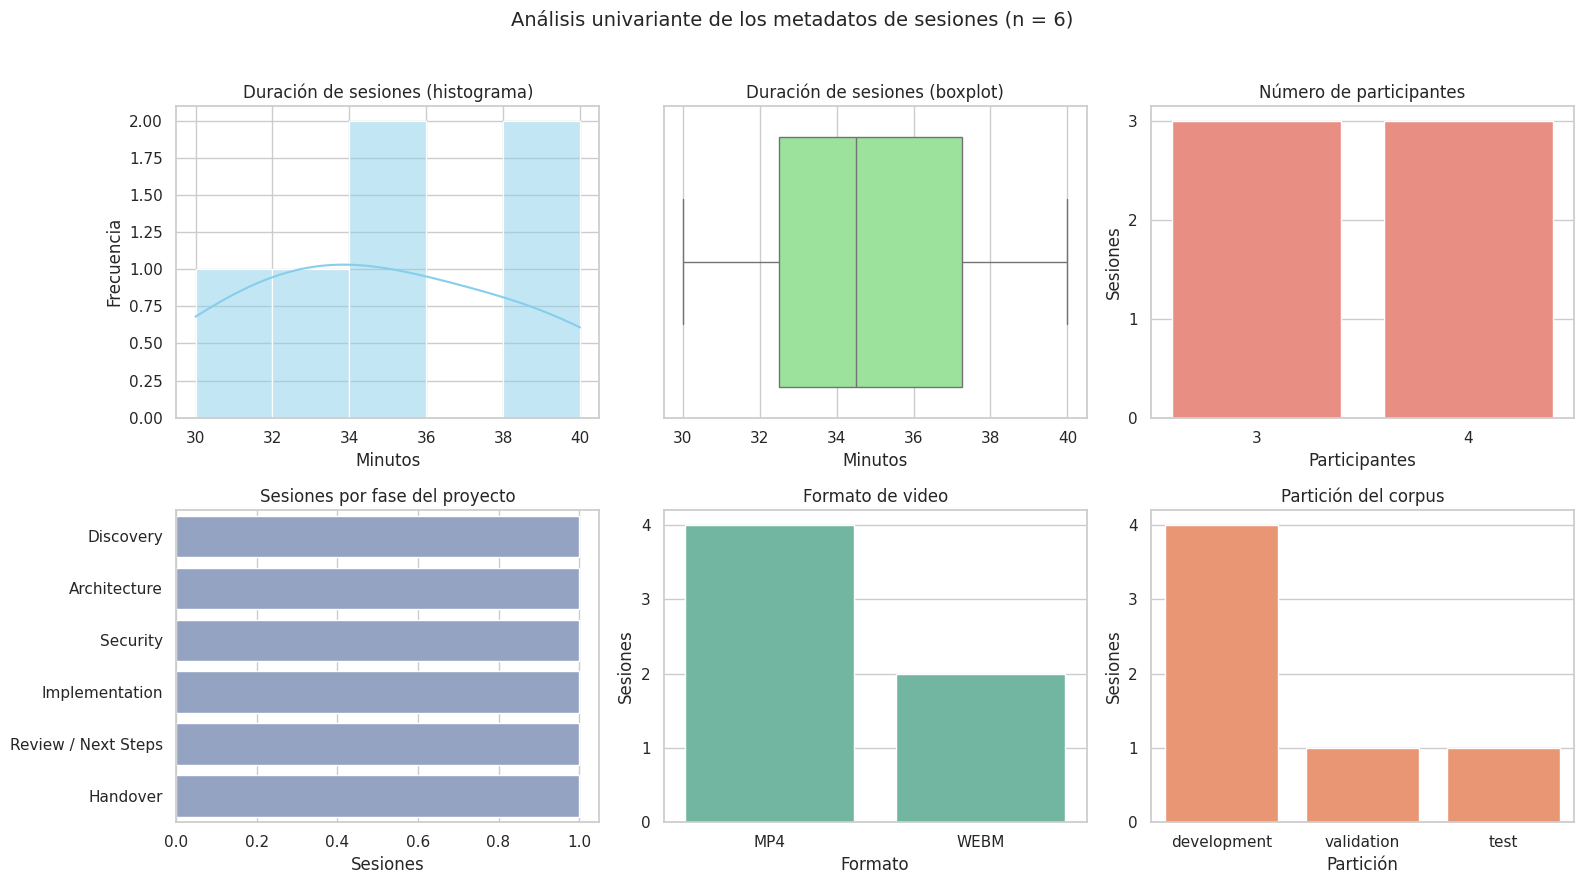

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Análisis univariante de los metadatos de sesiones (n = 6)", fontsize=14)

sns.histplot(sessions["duration_min"], bins=5, kde=True, ax=axes[0, 0], color="skyblue")
axes[0, 0].set(title="Duración de sesiones (histograma)", xlabel="Minutos", ylabel="Frecuencia")

sns.boxplot(x=sessions["duration_min"], ax=axes[0, 1], color="lightgreen")
axes[0, 1].set(title="Duración de sesiones (boxplot)", xlabel="Minutos")

sns.countplot(data=sessions, x="num_speakers", ax=axes[0, 2], color="salmon")
axes[0, 2].set(title="Número de participantes", xlabel="Participantes", ylabel="Sesiones")

sns.countplot(data=sessions, y="project_phase", ax=axes[1, 0], color="#8da0cb")
axes[1, 0].set(title="Sesiones por fase del proyecto", xlabel="Sesiones", ylabel="")

sns.countplot(data=sessions, x="video_format", ax=axes[1, 1], color="#66c2a5")
axes[1, 1].set(title="Formato de video", xlabel="Formato", ylabel="Sesiones")

sns.countplot(data=sessions, x="dataset_split", ax=axes[1, 2], color="#fc8d62")
axes[1, 2].set(title="Partición del corpus", xlabel="Partición", ylabel="Sesiones")

int_ticks(axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2])
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

**Valores atípicos en la duración.** Se usan dos criterios: el rango **IQR** (Q1 − 1,5·IQR, Q3 + 1,5·IQR) y el **rango esperado de 30 a 45 min**, que es un criterio de control del piloto (alcance de la muestra), no una regla estadística.

In [12]:
def outlier_table(df, cols, id_col):
    """Atípicos por regla IQR: límites, número de casos e identificadores."""
    rows = []
    for c in cols:
        s = df[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (df[c] < lo) | (df[c] > hi)
        rows.append({"variable": c, "q1": q1, "q3": q3, "limite_inf": round(lo, 1), "limite_sup": round(hi, 1),
                     "n_atipicos": int(mask.sum()), "ids": ", ".join(df.loc[mask, id_col].astype(str))})
    return pd.DataFrame(rows)


display(outlier_table(sessions, ["duration_min", "num_speakers"], "session_id"))

sessions["outside_expected_duration"] = ~sessions["duration_min"].between(30, 45)
q1, q3 = sessions["duration_min"].quantile([0.25, 0.75])
sessions["duration_outlier_iqr"] = ~sessions["duration_min"].between(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
display(sessions[["session_id", "duration_min", "outside_expected_duration", "duration_outlier_iqr"]])

,variable,q1,q3,limite_inf,limite_sup,n_atipicos,ids
0,duration_min,32.5,37.25,25.4,44.4,0,
1,num_speakers,3.0,4.00,1.5,5.5,0,


,session_id,duration_min,outside_expected_duration,duration_outlier_iqr
0,S01_DISCOVERY,35,False,False
1,S02_ARCH,40,False,False
2,S03_SECURITY,32,False,False
3,S04_IMPL,38,False,False
4,S05_REVIEW,30,False,False
5,S06_HANDOVER,34,False,False


### 4.2 Segmentos de transcripción (n = 30, sin eliminar nada todavía)

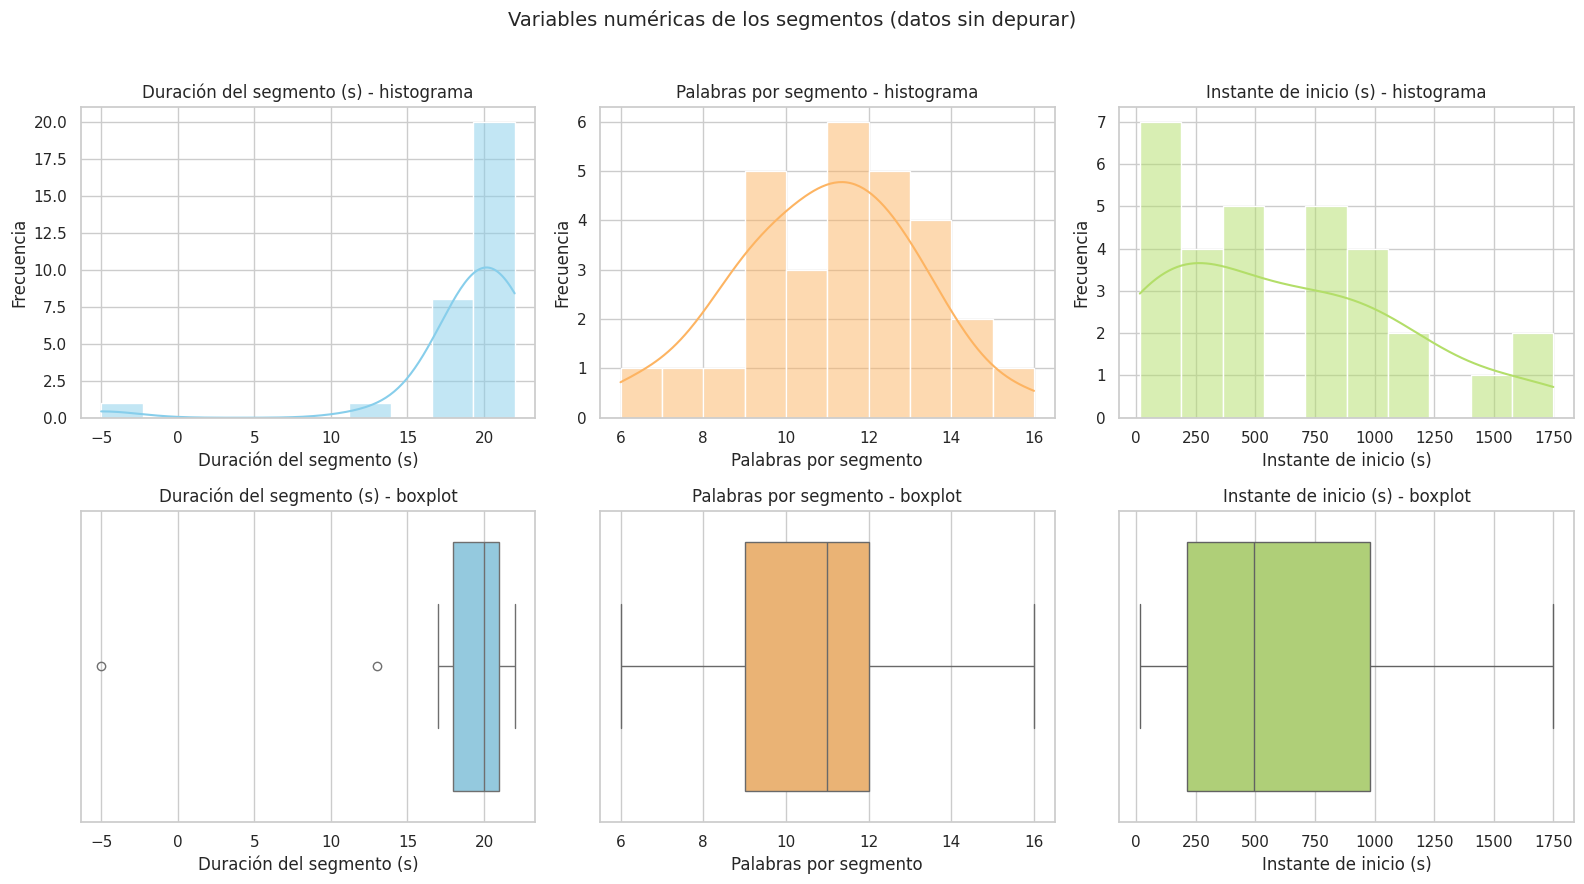

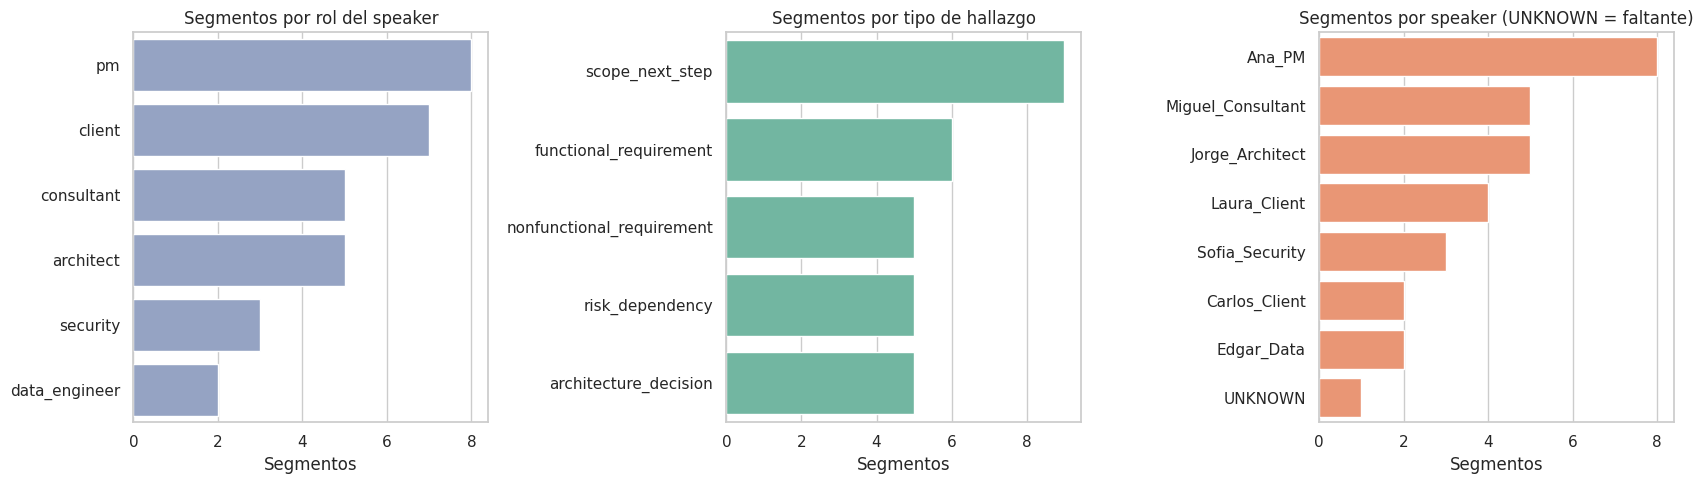

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Variables numéricas de los segmentos (datos sin depurar)", fontsize=14)

for j, (col, titulo, color) in enumerate([
    ("segment_duration_sec", "Duración del segmento (s)", "skyblue"),
    ("word_count", "Palabras por segmento", "#fdb462"),
    ("start_sec", "Instante de inicio (s)", "#b3de69"),
]):
    sns.histplot(segments[col].dropna(), bins=10, kde=True, ax=axes[0, j], color=color)
    axes[0, j].set(title=f"{titulo} - histograma", xlabel=titulo, ylabel="Frecuencia")
    sns.boxplot(x=segments[col], ax=axes[1, j], color=color)
    axes[1, j].set(title=f"{titulo} - boxplot", xlabel=titulo)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.countplot(data=segments, y="speaker_role", order=segments["speaker_role"].value_counts().index, ax=axes[0], color="#8da0cb")
axes[0].set(title="Segmentos por rol del speaker", xlabel="Segmentos", ylabel="")
sns.countplot(data=segments, y="expected_category", order=segments["expected_category"].value_counts().index, ax=axes[1], color="#66c2a5")
axes[1].set(title="Segmentos por tipo de hallazgo", xlabel="Segmentos", ylabel="")
sns.countplot(data=segments, y="speaker_clean", order=segments["speaker_clean"].value_counts().index, ax=axes[2], color="#fc8d62")
axes[2].set(title="Segmentos por speaker (UNKNOWN = faltante)", xlabel="Segmentos", ylabel="")
plt.tight_layout()
plt.show()

In [14]:
num_seg_cols = ["start_sec", "segment_duration_sec", "word_count", "estimated_tokens"]

print("Estadísticas descriptivas (datos sin depurar):")
display(segments[num_seg_cols].describe().round(2))

# Asimetría: >|1| sugeriría una transformación no lineal (log, raíz) antes de modelar.
mask_ok = ~segments["q_invalid_timestamp"] & ~segments["q_missing_text"]
skew_tbl = pd.DataFrame({
    "asimetria_todos": segments[num_seg_cols].skew(),
    "asimetria_sin_invalidos": segments.loc[mask_ok, num_seg_cols].skew(),
}).round(2)
print("Asimetría (skewness):")
display(skew_tbl)

print("Atípicos por regla IQR (datos sin depurar):")
display(outlier_table(segments, num_seg_cols, "segment_id"))

Estadísticas descriptivas (datos sin depurar):


,start_sec,segment_duration_sec,word_count,estimated_tokens
count,30.00,30.00,29.00,29.00
mean,620.60,19.00,10.97,19.03
std,505.64,4.95,2.21,2.96
min,15.00,-5.00,6.00,13.00
25%,211.25,18.00,9.00,16.00
50%,495.00,20.00,11.00,20.00
75%,980.00,21.00,12.00,21.00
max,1750.00,22.00,16.00,24.00


Asimetría (skewness):


,asimetria_todos,asimetria_sin_invalidos
start_sec,0.62,0.71
segment_duration_sec,-4.22,-1.34
word_count,-0.10,0.16
estimated_tokens,-0.38,-0.32


Atípicos por regla IQR (datos sin depurar):


,variable,q1,q3,limite_inf,limite_sup,n_atipicos,ids
0,start_sec,211.25,980.0,-941.9,2133.1,0,
1,segment_duration_sec,18.00,21.0,13.5,25.5,2,"SEG001, SEG017"
2,word_count,9.00,12.0,4.5,16.5,0,
3,estimated_tokens,16.00,21.0,8.5,28.5,0,


**Lectura.** El boxplot de duración del segmento marca dos puntos: SEG017, con duración **negativa** (fin menor que inicio, −5 s), y SEG001, un segmento corto de 13 s. El primero no es un atípico estadístico legítimo sino una **inconsistencia lógica** que además dispara la asimetría (−4,22 con todos los datos); el segundo es una variación normal. Las palabras por segmento (6–16) y el instante de inicio no muestran atípicos. Se corrige en la sección 5.

### 4.3 Conjunto de evaluación (gold) y documentos RAG

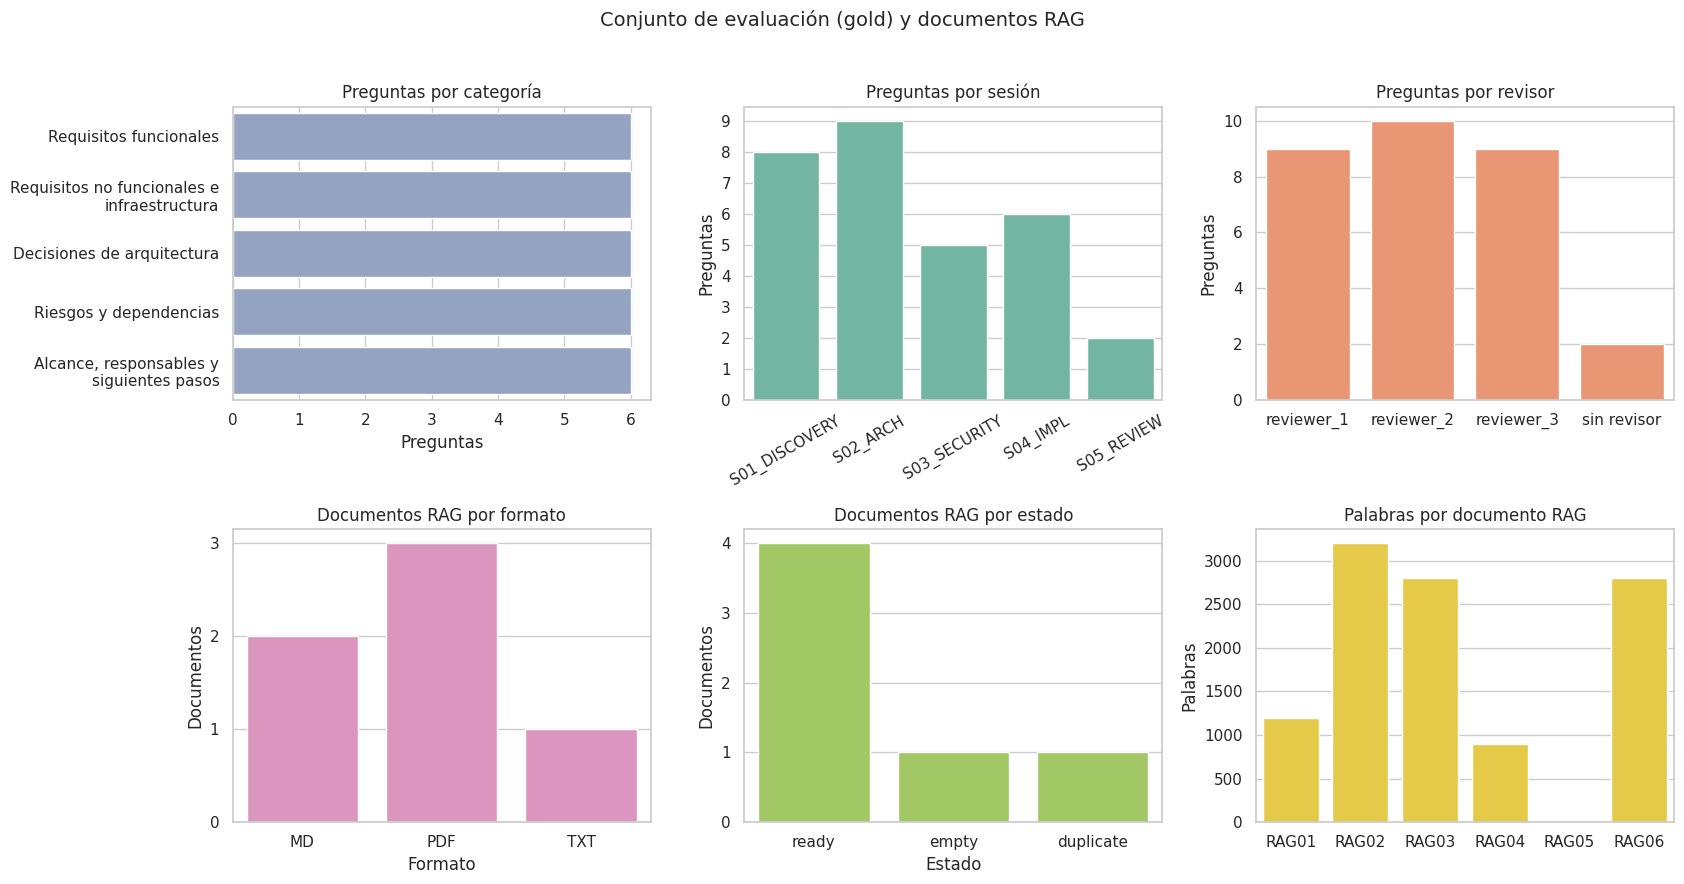

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
fig.suptitle("Conjunto de evaluación (gold) y documentos RAG", fontsize=14)

sns.countplot(data=gold, y="category", order=gold["category"].value_counts().index, ax=axes[0, 0], color="#8da0cb")
axes[0, 0].set(title="Preguntas por categoría", xlabel="Preguntas", ylabel="")
wrap_labels(axes[0, 0], 28)
int_ticks(axes[0, 0], axis="x")

sns.countplot(data=gold, x="session_id", order=sorted(gold["session_id"].unique()), ax=axes[0, 1], color="#66c2a5")
axes[0, 1].set(title="Preguntas por sesión", xlabel="", ylabel="Preguntas")
axes[0, 1].tick_params(axis="x", rotation=30)

sns.countplot(x=gold["reviewer"].fillna("sin revisor"), order=sorted(gold["reviewer"].fillna("sin revisor").unique()), ax=axes[0, 2], color="#fc8d62")
axes[0, 2].set(title="Preguntas por revisor", xlabel="", ylabel="Preguntas")

sns.countplot(data=rag_docs, x="file_format", ax=axes[1, 0], color="#e78ac3")
axes[1, 0].set(title="Documentos RAG por formato", xlabel="Formato", ylabel="Documentos")

sns.countplot(data=rag_docs, x="status", ax=axes[1, 1], color="#a6d854")
axes[1, 1].set(title="Documentos RAG por estado", xlabel="Estado", ylabel="Documentos")

sns.barplot(data=rag_docs, x="doc_id", y="word_count", ax=axes[1, 2], color="#ffd92f")
axes[1, 2].set(title="Palabras por documento RAG", xlabel="", ylabel="Palabras")
int_ticks(axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 4.4 Dimensión temporal

El corpus tiene dimensión de tiempo (`start_sec`/`end_sec` dentro de cada sesión). Se revisa **en qué parte de la sesión caen los segmentos** y qué fracción de cada sesión cubre la muestra.

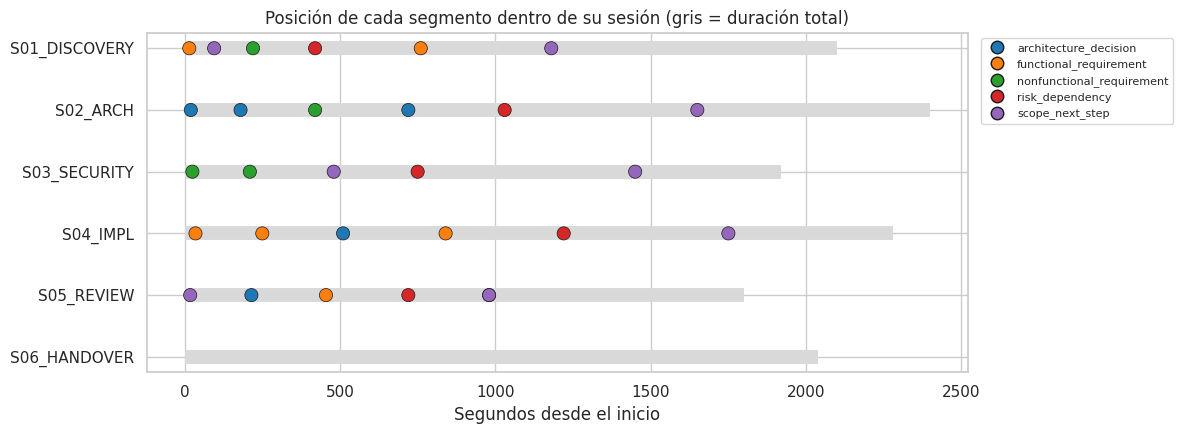

Segmentos que se solapan dentro de una misma sesión:


,session_id,segmento_1,segmento_2,segundos_solapados
0,S05_REVIEW,SEG029,SEG030,20


Cobertura de la muestra respecto a la duración de cada sesión:


,duracion_s,suma_bruta_s,temporal_unica_s,texto_util_s,suma_bruta_%,temporal_unica_%,texto_util_%
session_id,,,,,,,
S01_DISCOVERY,2100,104,104,104,5.0,5.0,5.0
S02_ARCH,2400,124,124,124,5.2,5.2,5.2
S03_SECURITY,1920,99,99,99,5.2,5.2,5.2
S04_IMPL,2280,127,127,127,5.6,5.6,5.6
S05_REVIEW,1800,121,101,80,6.7,5.6,4.4


S05: suma bruta 121.0 s -> descontando la copia (SEG030) 101.0 s -> descontando además el segmento sin texto (SEG028) 80.0 s
Verificación con los datos originales (121 -> 101 -> 80 s; 6,7 % -> 5,6 % -> 4,4 %): True


In [16]:
cats = sorted(segments["expected_category"].unique())
palette = dict(zip(cats, sns.color_palette("tab10", len(cats))))
order = list(sessions["session_id"])
ypos = {s: i for i, s in enumerate(order)}

fig, ax = plt.subplots(figsize=(12, 4.5))
for _, r in sessions.iterrows():
    ax.hlines(ypos[r["session_id"]], 0, r["duration_min"] * 60, color="#d9d9d9", linewidth=10, zorder=1)

seg_t = segments[~segments["q_invalid_timestamp"]]
ax.scatter(seg_t["start_sec"], seg_t["session_id"].map(ypos), c=seg_t["expected_category"].map(palette), s=90, zorder=3, edgecolor="k", linewidth=0.5)
ax.set_yticks(list(ypos.values()))
ax.set_yticklabels(list(ypos.keys()))
ax.invert_yaxis()
ax.set(title="Posición de cada segmento dentro de su sesión (gris = duración total)", xlabel="Segundos desde el inicio")
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=palette[c], markeredgecolor="k", markersize=9, label=c) for c in cats]
ax.legend(handles=handles, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

def union_seconds(intervals):
    """Segundos cubiertos por la UNIÓN de intervalos (un tramo solapado no se cuenta dos veces)."""
    total, cur_s, cur_e = 0, None, None
    for a, b in sorted(intervals):
        if cur_e is None or a > cur_e:
            if cur_e is not None:
                total += cur_e - cur_s
            cur_s, cur_e = a, b
        else:
            cur_e = max(cur_e, b)
    return total + (cur_e - cur_s if cur_e is not None else 0)


# 1) ¿Qué segmentos se solapan dentro de la misma sesión? (se revisan todos los pares, no solo los idénticos)
overlaps = []
for sid, g in seg_t.groupby("session_id"):
    filas = list(g[["segment_id", "start_sec", "end_sec"]].itertuples(index=False))
    for a_i in range(len(filas)):
        for b_i in range(a_i + 1, len(filas)):
            a, b = filas[a_i], filas[b_i]
            if a.start_sec < b.end_sec and b.start_sec < a.end_sec:
                overlaps.append([sid, a.segment_id, b.segment_id, min(a.end_sec, b.end_sec) - max(a.start_sec, b.start_sec)])
print("Segmentos que se solapan dentro de una misma sesión:")
display(pd.DataFrame(overlaps, columns=["session_id", "segmento_1", "segmento_2", "segundos_solapados"]))

# 2) Tres medidas distintas de cobertura (SEG017 queda fuera de todas: su intervalo es inválido)
#    - suma bruta: suma de duraciones (cuenta dos veces lo solapado)
#    - cobertura temporal única: unión de intervalos
#    - texto útil: unión de intervalos de segmentos con texto y que no son copia redundante
texto_util = ~seg_t["q_missing_text"] & ~seg_t["q_duplicate"]
dur_s = sessions.set_index("session_id")["duration_min"] * 60
filas = []
for sid, g in seg_t.groupby("session_id"):
    u = g[texto_util.loc[g.index]]
    filas.append([sid, dur_s[sid], int(g["segment_duration_sec"].sum()),
                  union_seconds(zip(g["start_sec"], g["end_sec"])),
                  union_seconds(zip(u["start_sec"], u["end_sec"]))])
cobertura = pd.DataFrame(filas, columns=["session_id", "duracion_s", "suma_bruta_s", "temporal_unica_s", "texto_util_s"]).set_index("session_id")
for col in ["suma_bruta", "temporal_unica", "texto_util"]:
    cobertura[f"{col}_%"] = (100 * cobertura[f"{col}_s"] / cobertura["duracion_s"]).round(1)
print("Cobertura de la muestra respecto a la duración de cada sesión:")
display(cobertura)

s5 = cobertura.loc["S05_REVIEW", ["suma_bruta_s", "temporal_unica_s", "texto_util_s"]].tolist()
print(f"S05: suma bruta {s5[0]} s -> descontando la copia (SEG030) {s5[1]} s -> descontando además el segmento sin texto (SEG028) {s5[2]} s")
print("Verificación con los datos originales (121 -> 101 -> 80 s; 6,7 % -> 5,6 % -> 4,4 %):", s5 == [121, 101, 80])


**Lectura.** Se distinguen tres medidas: la *suma bruta* de segundos (S05: 121 s = 6,7 %), la **cobertura temporal única** (unión de intervalos: SEG029 y SEG030 son idénticos y solo cuentan una vez, 101 s = 5,6 %) y la **cobertura de texto útil** (además excluye SEG028, que no tiene texto: 80 s = 4,4 %). SEG017 queda fuera de las tres porque su intervalo es inválido (fin < inicio). La única pareja solapada de toda la muestra es SEG029–SEG030; en las demás sesiones las tres medidas coinciden (5,0–5,6 %). Los segmentos son extractos breves y espaciados, es decir, un **muestreo disperso** y no una transcripción continua. Además, los segmentos de cada sesión siguen un orden visible (requisitos y decisiones al inicio; riesgos y siguientes pasos después). Se verá en la sección 6 si el tipo de hallazgo se asocia con el momento de la sesión.

## 5. Preprocesamiento

Principio: **eliminar solo lo que perjudica la calidad del contexto o no aporta información, no inventar datos y conservar la trazabilidad** (`session_id`, `segment_id`, `start_sec`, `end_sec`). Lo que requiere decisión humana se marca, no se rellena.

### 5.1 Segmentos: valores faltantes, inconsistencias, duplicados y markup

In [17]:
# Un segmento no sirve como input semántico si falta su texto, su tiempo es inválido o es una copia redundante.
segments["valid_for_semantic_input"] = ~(segments["q_missing_text"] | segments["q_invalid_timestamp"] | segments["q_duplicate"])

# Motivo de exclusión (prioridad: texto faltante > timestamp inválido > duplicado)
segments["exclusion_reason"] = np.select(
    [segments["q_missing_text"], segments["q_invalid_timestamp"], segments["q_duplicate"]],
    ["texto faltante", "timestamp inválido", "duplicado redundante"],
    default="",
)

segments_excluded = segments.loc[~segments["valid_for_semantic_input"],
                                 ["session_id", "segment_id", "start_sec", "end_sec", "speaker", "text_raw", "exclusion_reason"]]
print("Segmentos excluidos del input semántico (se guardan aparte para revisión humana):")
display(segments_excluded)

segments_clean = segments.loc[segments["valid_for_semantic_input"]].copy()
segments_clean["word_count"] = segments_clean["word_count"].astype(int)
segments_clean["estimated_tokens"] = segments_clean["estimated_tokens"].astype(int)

assert not segments_clean["text_clean"].str.contains("<|>", regex=True).any(), "Quedó markup en el texto limpio"
assert (segments_clean["end_sec"] > segments_clean["start_sec"]).all()

print(f"Segmentos originales: {len(segments)} -> válidos: {len(segments_clean)}  (excluidos: {len(segments) - len(segments_clean)}, {100 * (len(segments) - len(segments_clean)) / len(segments):.0f}%)")
print(f"Speakers sin identificar conservados como 'UNKNOWN': {(segments_clean['speaker_clean'] == 'UNKNOWN').sum()}")

print("\nAntes y después de limpiar el markup HTML:")
ej = segments.loc[segments["q_html_markup"], ["segment_id", "text_raw", "text_clean"]]
display(ej)

Segmentos excluidos del input semántico (se guardan aparte para revisión humana):


,session_id,segment_id,start_sec,end_sec,speaker,text_raw,exclusion_reason
16,S03_SECURITY,SEG017,1020,1015,Miguel_Consultant,La documentación autorizada deberá estar versionada.,timestamp inválido
27,S05_REVIEW,SEG028,720,741,Miguel_Consultant,NaN,texto faltante
29,S05_REVIEW,SEG030,980,1000,Ana_PM,Se revisará manualmente una muestra de respuestas para comparar co...,duplicado redundante


Segmentos originales: 30 -> válidos: 27  (excluidos: 3, 10%)
Speakers sin identificar conservados como 'UNKNOWN': 1

Antes y después de limpiar el markup HTML:


,segment_id,text_raw,text_clean
7,SEG008,<i>La arquitectura utilizará almacenamiento de objetos para conser...,La arquitectura utilizará almacenamiento de objetos para conservar...


**Justificación de las decisiones**

| Problema | Decisión | Por qué |
|---|---|---|
| **Texto faltante** (1 segmento, S05) | Excluir del input semántico; guardar en `segments_excluded` | Sin texto no hay contenido que el modelo pueda usar; imputarlo inventaría evidencia. La longitud queda como NaN y no como 0 para no sesgar las estadísticas |
| **Speaker faltante** (1 segmento, S01) | Marcar `UNKNOWN` y **conservar** | El texto y el `speaker_role` sí existen; atribuirlo a una persona sería falso, pero descartarlo perdería un requisito válido |
| **Timestamp inválido** (1 segmento, S03: fin < inicio) | Excluir y guardar para revisión | Es un error lógico, no un atípico estadístico. Podría ser un intercambio inicio/fin, pero sin verificarlo se rompería la trazabilidad a la evidencia |
| **Duplicado** (S05, mismo texto e intervalo) | Conservar la **primera** copia y excluir la redundante | Repetir evidencia consume contexto del modelo sin información nueva. Excluir *ambas* copias habría eliminado el contenido por completo |
| **Markup HTML** (1 segmento, S02) | Limpiar con `clean_text` en una columna nueva (`text_clean`) | Son etiquetas de formato sin significado de negocio; el texto original se conserva en `text_raw` |

### 5.1b Pruebas de calidad y limpieza

Se verifica por código que la limpieza hace exactamente lo que se declara: conteos, exclusiones con su motivo, conservación de una copia del duplicado, `UNKNOWN`, eliminación de markup **sin perder palabras** y trazabilidad (sesión, segmento e intervalo idénticos al original). Si una verificación falla, `assert_all_ok` lanza un `AssertionError` con la lista de fallas y **la exportación a `output/` se detiene** (ver sección 9). Al final se muestra una **prueba negativa** con datos corrompidos a propósito.

In [18]:
def run_quality_checks(raw, clean, excluded):
    """Devuelve una tabla (verificacion, ok, detalle) con las pruebas de calidad de los segmentos."""
    res = []

    def add(nombre, ok, detalle=""):
        res.append([nombre, bool(ok), str(detalle)])

    add("30 segmentos originales", len(raw) == 30, len(raw))
    add("27 segmentos válidos", len(clean) == 27, len(clean))
    add("Excluidos = {SEG017, SEG028, SEG030}", set(excluded["segment_id"]) == {"SEG017", "SEG028", "SEG030"}, sorted(excluded["segment_id"]))
    motivos = dict(zip(excluded["segment_id"], excluded["exclusion_reason"]))
    add("Motivo de cada exclusión", motivos == {"SEG017": "timestamp inválido", "SEG028": "texto faltante", "SEG030": "duplicado redundante"}, motivos)
    ids = set(clean["segment_id"])
    add("Duplicado: se conserva una sola copia (SEG029 sí, SEG030 no)", "SEG029" in ids and "SEG030" not in ids)
    add("Speaker faltante -> UNKNOWN (SEG005)", clean.loc[clean["segment_id"] == "SEG005", "speaker_clean"].tolist() == ["UNKNOWN"])
    add("Sin markup HTML en text_clean", not clean["text_clean"].str.contains(r"<[^>]+>", regex=True).any())
    raw_text = raw.set_index("segment_id")["text_raw"]
    perdidas = [r.segment_id for r in clean.itertuples()
                if re.sub(r"<[^>]+>", " ", str(raw_text[r.segment_id])).split() != r.text_clean.split()]
    add("Limpieza sin pérdida de palabras", not perdidas, perdidas or "sin diferencias")
    m = clean.merge(raw[["segment_id", "session_id", "start_sec", "end_sec"]], on="segment_id", how="left", suffixes=("", "_raw"))
    ref_ok = (m["session_id"] == m["session_id_raw"]) & (m["start_sec"] == m["start_sec_raw"]) & (m["end_sec"] == m["end_sec_raw"])
    add("Sesión e intervalo idénticos al original", ref_ok.all(), f"{int(ref_ok.sum())}/{len(m)}")
    add("segment_id únicos", clean["segment_id"].is_unique)
    add("Intervalos válidos (fin > inicio)", (clean["end_sec"] > clean["start_sec"]).all())
    return pd.DataFrame(res, columns=["verificacion", "ok", "detalle"])


def assert_all_ok(tabla):
    fallas = tabla[~tabla["ok"]]
    if len(fallas):
        raise AssertionError(f"Fallaron {len(fallas)} verificaciones: " + "; ".join(fallas["verificacion"]))


# --- Registros antes y después
claves = ["SEG005", "SEG008", "SEG017", "SEG028", "SEG029", "SEG030"]
antes_despues = segments.loc[segments["segment_id"].isin(claves),
                             ["segment_id", "session_id", "start_sec", "end_sec", "speaker", "text_raw",
                              "speaker_clean", "text_clean", "valid_for_semantic_input", "exclusion_reason"]]
print("Registros clave, antes (speaker/text_raw) y después (speaker_clean/text_clean):")
with pd.option_context("display.max_colwidth", 60, "display.width", 250):
    display(antes_despues)

# --- Verificaciones sobre el resultado real
checks_seg = run_quality_checks(segments, segments_clean, segments_excluded)
display(checks_seg)
assert_all_ok(checks_seg)
QUALITY_OK = True
print("Todas las verificaciones de segmentos pasaron.")

# --- Prueba negativa: ¿qué pasa si algo falla? (se corrompe una COPIA, los datos reales no se tocan)
bad = segments_clean.copy()
bad.loc[bad["segment_id"] == "SEG029", "start_sec"] = 0                                  # referencia temporal alterada
bad.loc[bad["segment_id"] == "SEG008", "text_clean"] = "<i>La arquitectura</i>"        # markup + palabras perdidas
bad = pd.concat([bad, segments.loc[segments["segment_id"] == "SEG030"]], ignore_index=True)  # se cuela el duplicado
tabla_mala = run_quality_checks(segments, bad, segments_excluded)
print("\nPrueba negativa -> verificaciones que fallan:")
display(tabla_mala[~tabla_mala["ok"]])
try:
    assert_all_ok(tabla_mala)
except AssertionError as e:
    print("AssertionError capturado (el pipeline se detendría y no exportaría nada):\n ", e)

Registros clave, antes (speaker/text_raw) y después (speaker_clean/text_clean):


,segment_id,session_id,start_sec,end_sec,speaker,text_raw,speaker_clean,text_clean,valid_for_semantic_input,exclusion_reason
4,SEG005,S01_DISCOVERY,760,780,NaN,El cliente también requiere descargar el resultado en PDF.,UNKNOWN,El cliente también requiere descargar el resultado en PDF.,True,
7,SEG008,S02_ARCH,180,202,Jorge_Architect,<i>La arquitectura utilizará almacenamiento de objetos p...,Jorge_Architect,La arquitectura utilizará almacenamiento de objetos para...,True,
16,SEG017,S03_SECURITY,1020,1015,Miguel_Consultant,La documentación autorizada deberá estar versionada.,Miguel_Consultant,La documentación autorizada deberá estar versionada.,False,timestamp inválido
27,SEG028,S05_REVIEW,720,741,Miguel_Consultant,NaN,Miguel_Consultant,,False,texto faltante
28,SEG029,S05_REVIEW,980,1000,Ana_PM,Se revisará manualmente una muestra de respuestas para c...,Ana_PM,Se revisará manualmente una muestra de respuestas para c...,True,
29,SEG030,S05_REVIEW,980,1000,Ana_PM,Se revisará manualmente una muestra de respuestas para c...,Ana_PM,Se revisará manualmente una muestra de respuestas para c...,False,duplicado redundante


,verificacion,ok,detalle
0,30 segmentos originales,True,30
1,27 segmentos válidos,True,27
2,"Excluidos = {SEG017, SEG028, SEG030}",True,"['SEG017', 'SEG028', 'SEG030']"
3,Motivo de cada exclusión,True,"{'SEG017': 'timestamp inválido', 'SEG028': 'texto faltante', 'SEG0..."
4,"Duplicado: se conserva una sola copia (SEG029 sí, SEG030 no)",True,
5,Speaker faltante -> UNKNOWN (SEG005),True,
6,Sin markup HTML en text_clean,True,
7,Limpieza sin pérdida de palabras,True,sin diferencias
8,Sesión e intervalo idénticos al original,True,27/27
9,segment_id únicos,True,


Todas las verificaciones de segmentos pasaron.

Prueba negativa -> verificaciones que fallan:


,verificacion,ok,detalle
1,27 segmentos válidos,False,28
4,"Duplicado: se conserva una sola copia (SEG029 sí, SEG030 no)",False,
6,Sin markup HTML en text_clean,False,
7,Limpieza sin pérdida de palabras,False,['SEG008']
8,Sesión e intervalo idénticos al original,False,27/28


AssertionError capturado (el pipeline se detendría y no exportaría nada):
  Fallaron 5 verificaciones: 27 segmentos válidos; Duplicado: se conserva una sola copia (SEG029 sí, SEG030 no); Sin markup HTML en text_clean; Limpieza sin pérdida de palabras; Sesión e intervalo idénticos al original


### 5.2 Valores atípicos y asimetría tras la depuración

In [19]:
num_clean_cols = ["start_sec", "segment_duration_sec", "word_count", "estimated_tokens"]

print("Atípicos por regla IQR (segmentos válidos):")
out_clean = outlier_table(segments_clean, num_clean_cols, "segment_id")
display(out_clean)

print("Asimetría (segmentos válidos):")
skew_clean = segments_clean[num_clean_cols].skew().round(2)
display(skew_clean.to_frame("asimetria"))

print("Atípicos en duración de sesión:", int(sessions["duration_outlier_iqr"].sum()),
      "| fuera del rango esperado 30-45 min:", int(sessions["outside_expected_duration"].sum()))

Atípicos por regla IQR (segmentos válidos):


,variable,q1,q3,limite_inf,limite_sup,n_atipicos,ids
0,start_sec,195.0,910.0,-877.5,1982.5,0,
1,segment_duration_sec,18.0,21.5,12.8,26.8,0,
2,word_count,9.5,12.0,5.8,15.8,1,SEG011
3,estimated_tokens,16.5,21.0,9.8,27.8,0,


Asimetría (segmentos válidos):


,asimetria
start_sec,0.79
segment_duration_sec,-1.31
word_count,0.25
estimated_tokens,-0.26


Atípicos en duración de sesión: 0 | fuera del rango esperado 30-45 min: 0


**Justificación (atípicos y transformaciones)**

- **Duración de sesiones:** ninguna sesión es atípica por IQR ni queda fuera del rango esperado de 30–45 min → **no se elimina ni modifica nada**.
- **Segmentos:** tras quitar el timestamp inválido desaparece el único valor realmente anómalo. El único punto que aún marca la regla IQR es SEG011 en `word_count` (16 palabras, con límite superior 15,8): es una frase algo más larga, **contenido legítimo** que se conserva; eliminarlo recortaría información semántica.
- **Transformaciones no lineales:** `word_count`, `estimated_tokens` y `start_sec` tienen |asimetría| < 1, así que **no se aplica log ni raíz**. La única excepción es `segment_duration_sec` (asimetría ≈ −1,31, sesgo moderado a la izquierda por unos pocos segmentos cortos como SEG001, 13 s). Tampoco se transforma: una transformación logarítmica corrige sesgos a la derecha, no a la izquierda; la variable es derivada de los timestamps (se elimina del conjunto final, sección 7); y el texto lo procesa un LLM, no un modelo lineal sensible a la escala.
- **Normalización/escalado:** no se aplica; estas variables se usan para describir volumen de contexto, no como entrada numérica de un modelo.

**Ejercicio de sensibilidad (hipotético, no modifica los datos).** En la muestra real ninguna sesión es atípica, así que no se ve cómo actuaría el criterio ante una. Para comprobarlo se agrega una sesión **hipotética** de 150 min *solo en una copia*; `sessions` y el CSV de entrada no se tocan.

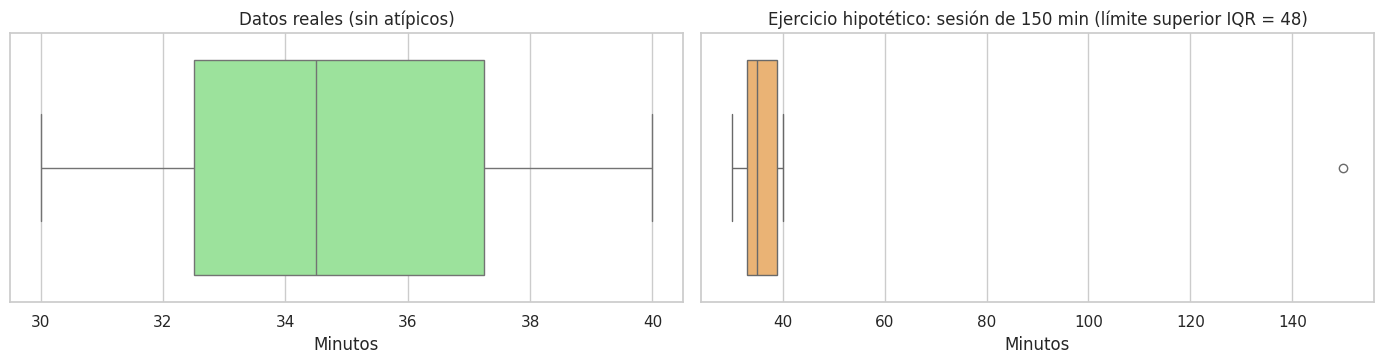

,session_id,duration_min,atipica_iqr,fuera_30_45
6,S_DEMO (hipotética),150,True,True


Datos reales intactos: 6 sesiones, duración máxima 40 min.


In [20]:
demo = pd.concat([sessions[["session_id", "duration_min"]],
                  pd.DataFrame({"session_id": ["S_DEMO (hipotética)"], "duration_min": [150]})], ignore_index=True)
qd1, qd3 = demo["duration_min"].quantile([0.25, 0.75])
lo_d, hi_d = qd1 - 1.5 * (qd3 - qd1), qd3 + 1.5 * (qd3 - qd1)
demo["atipica_iqr"] = ~demo["duration_min"].between(lo_d, hi_d)
demo["fuera_30_45"] = ~demo["duration_min"].between(30, 45)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
sns.boxplot(x=sessions["duration_min"], ax=axes[0], color="lightgreen")
axes[0].set(title="Datos reales (sin atípicos)", xlabel="Minutos")
sns.boxplot(x=demo["duration_min"], ax=axes[1], color="#fdb462")
axes[1].set(title=f"Ejercicio hipotético: sesión de 150 min (límite superior IQR = {hi_d:.0f})", xlabel="Minutos")
plt.tight_layout()
plt.show()

display(demo[demo["atipica_iqr"] | demo["fuera_30_45"]])
assert len(sessions) == 6 and sessions["duration_min"].max() == 40, "Los datos reales no deben modificarse"
print("Datos reales intactos: 6 sesiones, duración máxima 40 min.")

**Lectura.** Con una sesión de 150 min el criterio la marcaría como atípica tanto por IQR como por salir del rango de 30–45 min. La estrategia sería **marcarla, no eliminarla**: es una reunión con contenido válido, y lo que cambia es el tratamiento (dividirla en *chunks* para no exceder la ventana de contexto del modelo). En cambio, una llamada de pocos minutos (caída de conexión) sí podría descartarse como ruido tras revisarla.

### 5.3 Sesiones, gold y documentos RAG

In [21]:
# ---- Sesiones: la sesión sin transcripción se conserva marcada, no se imputa ----
sessions_clean = sessions.copy()
sessions_clean["usable_for_text"] = sessions_clean["has_transcript"] & sessions_clean["session_id"].isin(segments_clean["session_id"])
display(sessions_clean[["session_id", "project_phase", "dataset_split", "has_transcript", "usable_for_text"]])

# ---- Gold: no se descartan preguntas; se marca el estado de revisión y se valida la evidencia ----
gold_clean = gold.copy()
gold_clean["review_status"] = np.where(gold_clean["q_missing_reviewer"], "pending_review", "reviewer_assigned")
gold_clean["evidence_segment_id"] = gold_clean["evidence_reference"].str.split("#").str[1]
gold_clean["evidence_available"] = gold_clean["evidence_segment_id"].isin(segments_clean["segment_id"])

# La respuesta esperada se copió del texto crudo del segmento, así que arrastra su markup (p. ej. Q014).
gold_clean["expected_answer_clean"] = gold_clean["expected_answer"].apply(clean_text)
gold_clean["question_clean"] = gold_clean["question"].apply(clean_text)
print("Preguntas del gold con markup HTML antes de limpiar:")
display(gold_clean.loc[gold_clean["q_html_markup"], ["question_id", "expected_answer", "expected_answer_clean"]])

# Las categorías del gold están en español y las de segments en inglés: se unifican con un mapeo explícito.
CATEGORY_MAP = {
    "functional_requirement": "Requisitos funcionales",
    "nonfunctional_requirement": "Requisitos no funcionales e infraestructura",
    "architecture_decision": "Decisiones de arquitectura",
    "risk_dependency": "Riesgos y dependencias",
    "scope_next_step": "Alcance, responsables y siguientes pasos",
}
assert set(CATEGORY_MAP) == set(segments["expected_category"].unique()), "Hay categorías sin mapear"
assert set(CATEGORY_MAP.values()) == set(gold["category"].unique()), "Hay categorías del gold sin mapear"
segments_clean["category_es"] = segments_clean["expected_category"].map(CATEGORY_MAP)

check = gold_clean.merge(segments_clean[["segment_id", "category_es", "text_clean"]], left_on="evidence_segment_id", right_on="segment_id", how="left")
print(f"Preguntas con evidencia disponible en segmentos válidos: {int(gold_clean['evidence_available'].sum())} de {len(gold_clean)}")
print(f"Preguntas cuya categoría coincide con la del segmento de evidencia: {int((check['category'] == check['category_es']).sum())} de {len(check)}")
print(f"Respuestas esperadas (ya limpias) idénticas al texto limpio de su segmento de evidencia: {int((check['expected_answer_clean'] == check['text_clean']).sum())} de {len(check)}")
print(f"Preguntas pendientes de revisión humana: {int((gold_clean['review_status'] == 'pending_review').sum())}")
display(gold_clean.loc[gold_clean["review_status"] == "pending_review", ["question_id", "session_id", "evidence_reference", "review_status"]])

# ---- RAG: vacío y duplicado no deben entrar al índice ----
rag_clean = rag_docs.copy()
rag_clean["index_eligible"] = (rag_clean["status"] == "ready") & (rag_clean["word_count"] > 0)
display(rag_clean[["doc_id", "document_type", "status", "word_count", "duplicate_of", "index_eligible"]])
print(f"Documentos elegibles para el índice: {int(rag_clean['index_eligible'].sum())} de {len(rag_clean)} "
      f"({int(rag_clean.loc[rag_clean['index_eligible'], 'word_count'].sum())} palabras)")

,session_id,project_phase,dataset_split,has_transcript,usable_for_text
0,S01_DISCOVERY,Discovery,development,True,True
1,S02_ARCH,Architecture,development,True,True
2,S03_SECURITY,Security,development,True,True
3,S04_IMPL,Implementation,development,True,True
4,S05_REVIEW,Review / Next Steps,validation,True,True
5,S06_HANDOVER,Handover,test,False,False


Preguntas del gold con markup HTML antes de limpiar:


,question_id,expected_answer,expected_answer_clean
13,Q014,<i>La arquitectura utilizará almacenamiento de objetos para conser...,La arquitectura utilizará almacenamiento de objetos para conservar...


Preguntas con evidencia disponible en segmentos válidos: 30 de 30
Preguntas cuya categoría coincide con la del segmento de evidencia: 30 de 30
Respuestas esperadas (ya limpias) idénticas al texto limpio de su segmento de evidencia: 30 de 30
Preguntas pendientes de revisión humana: 2


,question_id,session_id,evidence_reference,review_status
7,Q008,S02_ARCH,S02_ARCH#SEG009,pending_review
23,Q024,S02_ARCH,S02_ARCH#SEG011,pending_review


,doc_id,document_type,status,word_count,duplicate_of,index_eligible
0,RAG01,TDD Template,ready,1200,NaN,True
1,RAG02,Architecture Guidelines,ready,3200,NaN,True
2,RAG03,Security Guidelines,ready,2800,NaN,True
3,RAG04,Delivery Checklist,ready,900,NaN,True
4,RAG05,Empty Placeholder,empty,0,NaN,False
5,RAG06,Security Guidelines Copy,duplicate,2800,RAG03,False


Documentos elegibles para el índice: 4 de 6 (8100 palabras)


**Justificación**

- **Sesión sin transcripción (S06, partición `test`):** se conserva la fila con `usable_for_text = False`. Rellenarla con texto vacío la haría parecer una reunión sin contenido; es mejor que quede explícito que **no hay datos**. Consecuencia importante: hoy la partición de prueba está vacía.
- **Markup en el gold (Q014):** la `expected_answer` de Q014 arrastra las etiquetas `<i>…</i><br>` del segmento SEG008. Se limpia con la misma `clean_text` en una columna nueva (`expected_answer_clean`), conservando el original; así la respuesta de referencia queda comparable con el texto que verá el modelo.
- **Preguntas sin revisor:** se conservan con `review_status = pending_review` en lugar de borrarlas. Las otras 28 quedan como `reviewer_assigned`: el CSV solo registra un nombre de reviewer, **no acredita por sí mismo que la revisión se haya hecho**; el equipo debe aportar ese respaldo (quién, cuándo, con qué criterio).
- **Documentos RAG:** el documento vacío y la copia duplicada se marcan como no elegibles. Un documento vacío no aporta recuperación y un duplicado infla el índice sin conocimiento nuevo.

### 5.3b Auditoría del conjunto de referencia (las 30 preguntas completas)

Se muestran las 30 filas con pregunta, respuesta esperada y fuente, y se comprueba por código que cada respuesta está respaldada por su evidencia: el segmento existe, pertenece a la misma sesión, el intervalo coincide y el texto limpio es idéntico. **Esto verifica trazabilidad, no calidad semántica**: una respuesta idéntica al segmento fuente no demuestra por sí sola que la pregunta sea buena ni mide el desempeño del asistente.

In [22]:
seg_ref = segments[["segment_id", "session_id", "start_sec", "end_sec", "text_clean"]].rename(
    columns={"session_id": "seg_session", "start_sec": "seg_start", "end_sec": "seg_end", "text_clean": "seg_text"})
audit = gold_clean.merge(seg_ref, left_on="evidence_segment_id", right_on="segment_id", how="left")
audit["ok_sesion"] = audit["session_id"] == audit["seg_session"]
audit["ok_intervalo"] = (audit["timestamp_start_sec"] == audit["seg_start"]) & (audit["timestamp_end_sec"] == audit["seg_end"])
audit["ok_respuesta"] = audit["expected_answer_clean"] == audit["seg_text"]
audit["evidencia_en_validos"] = audit["evidence_segment_id"].isin(segments_clean["segment_id"])
audit["pregunta_plantilla"] = audit["question"].str.match(r"^Pregunta sintética \d+ sobre")
audit["intervalo"] = audit["timestamp_start_sec"].astype(str) + "–" + audit["timestamp_end_sec"].astype(str) + " s"

with pd.option_context("display.max_colwidth", None, "display.width", 300, "display.max_rows", 40):
    display(audit[["question_id", "session_id", "question", "expected_answer_clean", "evidence_reference",
                   "intervalo", "reviewer", "review_status"]])

checks_gold = pd.DataFrame([
    ["30 preguntas", len(audit) == 30, len(audit)],
    ["La evidencia existe en segmentos válidos", audit["evidencia_en_validos"].all(), f"{int(audit['evidencia_en_validos'].sum())}/30"],
    ["La sesión de la pregunta = sesión del segmento", audit["ok_sesion"].all(), f"{int(audit['ok_sesion'].sum())}/30"],
    ["El intervalo coincide con el del segmento", audit["ok_intervalo"].all(), f"{int(audit['ok_intervalo'].sum())}/30"],
    ["Respuesta (limpia) = texto limpio del segmento", audit["ok_respuesta"].all(), f"{int(audit['ok_respuesta'].sum())}/30"],
], columns=["verificacion", "ok", "detalle"])
display(checks_gold)
assert_all_ok(checks_gold)
QUALITY_OK = QUALITY_OK and bool(checks_gold["ok"].all())

print("Hallazgos del conjunto de referencia (no son fallas del código, son pendientes de contenido):")
print(f"- Preguntas con texto genérico de plantilla ('Pregunta sintética N sobre ...'): {int(audit['pregunta_plantilla'].sum())} de 30 -> faltan preguntas concretas.")
print(f"- Con reviewer asignado en el CSV: {int((audit['review_status'] == 'reviewer_assigned').sum())}; pendientes: {audit.loc[audit['review_status'] == 'pending_review', 'question_id'].tolist()}.")
print("- El CSV solo guarda un nombre de reviewer: no hay fecha, criterio ni acta que acredite la revisión humana.")

,question_id,session_id,question,expected_answer_clean,evidence_reference,intervalo,reviewer,review_status
0,Q001,S01_DISCOVERY,Pregunta sintética 1 sobre requisitos funcionales.,Necesitamos que el portal permita consultar el estado de cada solicitud.,S01_DISCOVERY#SEG001,15–28 s,reviewer_2,reviewer_assigned
1,Q002,S01_DISCOVERY,Pregunta sintética 2 sobre requisitos funcionales.,El cliente también requiere descargar el resultado en PDF.,S01_DISCOVERY#SEG005,760–780 s,reviewer_3,reviewer_assigned
2,Q003,S04_IMPL,Pregunta sintética 3 sobre requisitos funcionales.,"El sistema deberá extraer requisitos, decisiones, riesgos y siguientes pasos.",S04_IMPL#SEG019,35–54 s,reviewer_1,reviewer_assigned
3,Q004,S04_IMPL,Pregunta sintética 4 sobre requisitos funcionales.,Cada hallazgo deberá incluir el identificador de sesión y su intervalo temporal.,S04_IMPL#SEG020,250–272 s,reviewer_2,reviewer_assigned
4,Q005,S04_IMPL,Pregunta sintética 5 sobre requisitos funcionales.,El agente auditor deberá detectar afirmaciones sin evidencia.,S04_IMPL#SEG022,840–862 s,reviewer_3,reviewer_assigned
5,Q006,S05_REVIEW,Pregunta sintética 6 sobre requisitos funcionales.,El usuario debe poder identificar de dónde proviene cada afirmación relevante.,S05_REVIEW#SEG027,455–475 s,reviewer_1,reviewer_assigned
6,Q007,S01_DISCOVERY,Pregunta sintética 7 sobre requisitos no funcionales e infraestructura.,La solución debe responder en menos de tres segundos para las consultas principales.,S01_DISCOVERY#SEG003,220–238 s,reviewer_2,reviewer_assigned
7,Q008,S02_ARCH,Pregunta sintética 8 sobre requisitos no funcionales e infraestructura.,La solución debe conservar trazabilidad de cada requisito hasta su evidencia.,S02_ARCH#SEG009,420–441 s,NaN,pending_review
8,Q009,S03_SECURITY,Pregunta sintética 9 sobre requisitos no funcionales e infraestructura.,Se requiere cifrado de la información en tránsito y en reposo.,S03_SECURITY#SEG013,25–43 s,reviewer_1,reviewer_assigned
9,Q010,S03_SECURITY,Pregunta sintética 10 sobre requisitos no funcionales e infraestructura.,Los accesos al sistema deben quedar registrados para auditoría.,S03_SECURITY#SEG014,210–230 s,reviewer_2,reviewer_assigned


,verificacion,ok,detalle
0,30 preguntas,True,30
1,La evidencia existe en segmentos válidos,True,30/30
2,La sesión de la pregunta = sesión del segmento,True,30/30
3,El intervalo coincide con el del segmento,True,30/30
4,Respuesta (limpia) = texto limpio del segmento,True,30/30


Hallazgos del conjunto de referencia (no son fallas del código, son pendientes de contenido):
- Preguntas con texto genérico de plantilla ('Pregunta sintética N sobre ...'): 30 de 30 -> faltan preguntas concretas.
- Con reviewer asignado en el CSV: 28; pendientes: ['Q008', 'Q024'].
- El CSV solo guarda un nombre de reviewer: no hay fecha, criterio ni acta que acredite la revisión humana.


### 5.4 Alta cardinalidad

In [23]:
alta = cardinality[cardinality["tipo"] == "ALTA cardinalidad"]
ident = cardinality[cardinality["rol"] == "id"]
unica = cardinality[cardinality["tipo"].str.startswith("única")]

print("Variables con alta cardinalidad:", alta["columna"].tolist() or "ninguna")
print("Identificadores / claves de trazabilidad:", ident["tabla"].str.cat(ident["columna"], sep=".").tolist())
print("Categóricas únicas por fila solo por n = 6:", unica["tabla"].str.cat(unica["columna"], sep=".").tolist())
print(f"Cardinalidad máxima de una categórica reutilizable: {cardinality.loc[cardinality['tipo'] == 'baja / moderada', 'valores_unicos'].max()} clases")
print(f"speaker ({segments['speaker'].nunique()} nombres) vs speaker_role ({segments['speaker_role'].nunique()} roles)")

Variables con alta cardinalidad: ninguna
Identificadores / claves de trazabilidad: ['sessions.session_id', 'segments.session_id', 'segments.segment_id', 'gold.question_id', 'gold.session_id', 'gold.evidence_reference', 'rag_docs.doc_id']
Categóricas únicas por fila solo por n = 6: ['sessions.project_phase', 'rag_docs.document_type']
Cardinalidad máxima de una categórica reutilizable: 7 clases
speaker (7 nombres) vs speaker_role (6 roles)


**Justificación.** **No hay variables categóricas de alta cardinalidad**: las que se repiten tienen como máximo 7 clases (`speaker`), así que no se necesita agrupar categorías raras ni aplicar *target encoding*. Dos columnas (`project_phase` y `document_type`) resultan únicas por fila **solo porque la muestra tiene 6 filas**; con el corpus real serán categorías reutilizables (fases del proyecto, tipos de documento), por lo que conviene volver a revisar su cardinalidad entonces. Las claves (`segment_id`, `question_id`, `evidence_reference`, …) son **identificadores de trazabilidad**, no variables explicativas: se conservan como metadatos pero no entran como característica. `evidence_reference` no es totalmente única (25 valores para 30 preguntas) porque cinco segmentos son citados por dos preguntas cada uno. Para el contexto del modelo se prefiere `speaker_role` al nombre propio `speaker` (más estable y sin datos personales).

### 5.5 Tabla resumen de decisiones de preprocesamiento

In [24]:
n = lambda mask: int(mask.sum())

preprocessing_decisions = pd.DataFrame([
    ["segments", "Texto faltante", n(segments["q_missing_text"]), "Excluir del input; guardar en segments_excluded", "Sin texto no hay contenido; no se inventa evidencia"],
    ["segments", "Speaker faltante", n(segments["q_missing_speaker"]), "Marcar UNKNOWN y conservar", "El texto y el rol son válidos; no se atribuye a una persona"],
    ["segments", "Timestamp inválido", n(segments["q_invalid_timestamp"]), "Excluir; revisión humana", "Inconsistencia lógica; protege la trazabilidad"],
    ["segments", "Duplicado", n(segments["q_duplicate"]), "Conservar primera copia", "Evita repetir evidencia sin perder el contenido"],
    ["segments", "Markup HTML", n(segments["q_html_markup"]), "clean_text en columna nueva", "Ruido de formato; el original se conserva"],
    ["segments", "Atípicos estadísticos (IQR) tras depurar", int(out_clean["n_atipicos"].sum()), "Conservar", "Variación legítima de longitud de frase"],
    ["segments", f"Asimetría (segment_duration_sec = {skew_clean['segment_duration_sec']:.2f})", int((skew_clean.abs() > 1).sum()), "Sin transformación", "Sesgo izquierdo moderado; variable derivada que se elimina; las demás |skew| < 1"],
    ["sessions", "Sesión sin transcripción", n(~sessions["has_transcript"]), "Conservar con usable_for_text = False", "No se imputan datos inexistentes"],
    ["sessions", "Duración atípica", n(sessions["duration_outlier_iqr"] | sessions["outside_expected_duration"]), "Ninguna acción", "Todas dentro de IQR y del rango 30-45 min"],
    ["gold", "Revisor faltante", n(gold["q_missing_reviewer"]), "review_status = pending_review", "Se conserva la pregunta, se condiciona su uso"],
    ["gold", "Markup HTML en respuesta (Q014)", n(gold["q_html_markup"]), "clean_text en expected_answer_clean", "La referencia debe ser comparable con el texto limpio del modelo"],
    ["gold/segments", "Categorías en idiomas distintos", len(CATEGORY_MAP), "Mapeo EN -> ES explícito", "Permite cruzar gold con segmentos"],
    ["rag_docs", "Documento vacío", n(rag_docs["q_empty"]), "index_eligible = False", "No aporta recuperación"],
    ["rag_docs", "Documento duplicado", n(rag_docs["q_duplicate"]), "index_eligible = False", "Infla el índice sin conocimiento nuevo"],
    ["todas", "Alta cardinalidad", len(alta), "No aplica", "Categóricas con pocas clases; identificadores solo como metadatos"],
], columns=["tabla", "problema", "casos", "decision", "justificacion"])

display(preprocessing_decisions)

,tabla,problema,casos,decision,justificacion
0,segments,Texto faltante,1,Excluir del input; guardar en segments_excluded,Sin texto no hay contenido; no se inventa evidencia
1,segments,Speaker faltante,1,Marcar UNKNOWN y conservar,El texto y el rol son válidos; no se atribuye a una persona
2,segments,Timestamp inválido,1,Excluir; revisión humana,Inconsistencia lógica; protege la trazabilidad
3,segments,Duplicado,1,Conservar primera copia,Evita repetir evidencia sin perder el contenido
4,segments,Markup HTML,1,clean_text en columna nueva,Ruido de formato; el original se conserva
5,segments,Atípicos estadísticos (IQR) tras depurar,1,Conservar,Variación legítima de longitud de frase
6,segments,Asimetría (segment_duration_sec = -1.31),1,Sin transformación,Sesgo izquierdo moderado; variable derivada que se elimina; las de...
7,sessions,Sesión sin transcripción,1,Conservar con usable_for_text = False,No se imputan datos inexistentes
8,sessions,Duración atípica,0,Ninguna acción,Todas dentro de IQR y del rango 30-45 min
9,gold,Revisor faltante,2,review_status = pending_review,"Se conserva la pregunta, se condiciona su uso"


## 6. Análisis bi/multivariante

En esta etapa **no existe una variable objetivo supervisada**; la columna `expected_category` actúa como etiqueta de referencia del corpus sintético (no es una predicción de un modelo). Se exploran las relaciones que podrían afectar la operación futura del sistema, con análisis **cuantitativo (coeficientes, p-values, V de Cramér) y gráfico (heatmaps, dispersión, boxplots)**.

**Método, unidad de análisis y número de observaciones**

| Análisis | Unidad | n | Método |
|---|---|---|---|
| 6.1 Correlación a nivel sesión | sesión con transcripción | 5 | Spearman (principal) y Pearson (comparación); p **exacto por permutación** |
| 6.2 Correlación a nivel segmento | segmento válido | 27 (anidados en 5 sesiones) | Spearman; p asintótico solo orientativo |
| 6.3 Asociación categórica | segmento válido | 27 | Tablas cruzadas y V de Cramér (descriptiva) |
| 6.3 Numérica vs. categoría | segmento válido | 27 en 5 grupos de 4 a 8 | Kruskal-Wallis, con tamaño del efecto (ε²) |

**Precauciones.** (1) Los segmentos están **agrupados por sesión**, así que no son observaciones independientes y los p-values son optimistas. (2) El corpus fue **diseñado manualmente**: las relaciones reflejan en parte cómo se construyó. (3) Con n = 5 el p-value asintótico que calcula `scipy` (aproximación t) **no es confiable**; por eso se calcula el p exacto enumerando las 5! = 120 ordenaciones, cuyo mínimo posible es 2/120 ≈ 0,017 (|rho| = 1). (4) Un resultado **no significativo no demuestra** que los grupos sean iguales ni que no haya diferencias relevantes: solo indica que la muestra no basta para detectarlas. Todo se interpreta como **patrón descriptivo**, no como inferencia sobre reuniones reales.

### 6.1 Nivel sesión: duración, participantes y volumen de texto

,session_id,duration_min,num_speakers,dataset_split,has_transcript,num_segments,total_words,estimated_tokens,visual_references
0,S01_DISCOVERY,35,4,development,True,6.0,58.0,99.0,0.0
1,S02_ARCH,40,4,development,True,6.0,75.0,127.0,1.0
2,S03_SECURITY,32,3,development,True,5.0,57.0,96.0,0.0
3,S04_IMPL,38,4,development,True,6.0,63.0,115.0,0.0
4,S05_REVIEW,30,3,validation,True,4.0,46.0,80.0,0.0
5,S06_HANDOVER,34,3,test,False,0.0,0.0,0.0,0.0


Correlaciones a nivel sesión (n = 5; solo descriptivas):


,variable_1,variable_2,n,spearman,p_asintotico,p_exacto
0,duration_min,num_speakers,5,0.87,0.058,0.200
1,duration_min,num_segments,5,0.89,0.041,0.100
2,duration_min,total_words,5,1.00,0.000,0.017
3,num_speakers,num_segments,5,0.97,0.007,0.100
4,num_speakers,total_words,5,0.87,0.058,0.200
5,num_segments,total_words,5,0.89,0.041,0.100


p_asintotico = aproximación de scipy (no confiable con n = 5). p_exacto = permutación sobre las 120 ordenaciones; su mínimo posible es 0.017 (|rho| = 1).


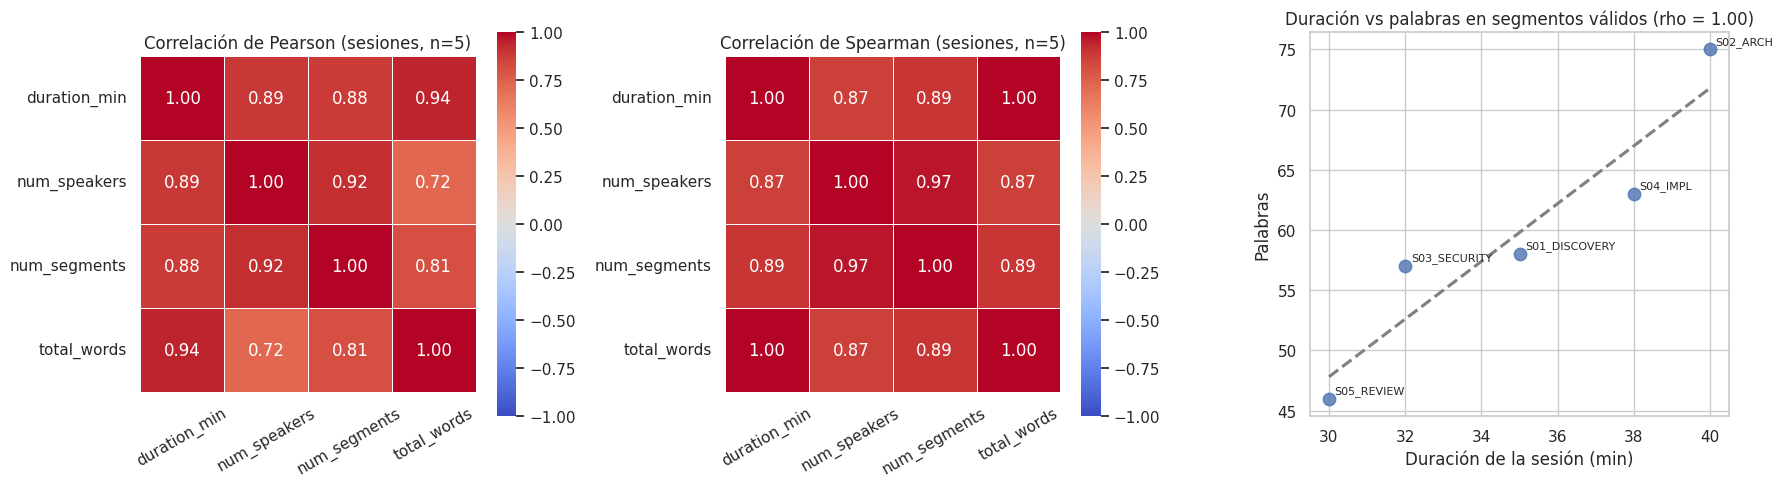

In [25]:
import itertools
import math

# Resumen de la transcripción válida por sesión. El LEFT JOIN conserva la sesión sin transcripción.
session_summary = (
    segments_clean.groupby("session_id")
    .agg(num_segments=("segment_id", "count"), total_words=("word_count", "sum"),
         estimated_tokens=("estimated_tokens", "sum"), visual_references=("has_visual_reference", "sum"))
    .reset_index()
)
session_summary = sessions[["session_id", "duration_min", "num_speakers", "dataset_split", "has_transcript"]].merge(
    session_summary, on="session_id", how="left"
).fillna({"num_segments": 0, "total_words": 0, "estimated_tokens": 0, "visual_references": 0})
display(session_summary)

usable = session_summary[session_summary["total_words"] > 0]
sess_cols = ["duration_min", "num_speakers", "num_segments", "total_words"]


def exact_spearman_p(x, y):
    """p bilateral EXACTO por permutación (todas las n! ordenaciones de y). Solo para n pequeño (n <= 8)."""
    x = np.asarray(x)
    r_obs = abs(spearmanr(x, y)[0])
    cuenta = total = 0
    for perm in itertools.permutations(np.asarray(y)):
        total += 1
        if abs(spearmanr(x, perm)[0]) >= r_obs - 1e-12:
            cuenta += 1
    return cuenta / total


def corr_table(df, cols, method="spearman", exact=False):
    fn = spearmanr if method == "spearman" else pearsonr
    rows = []
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            r, p = fn(df[a], df[b])
            fila = [a, b, len(df), round(float(r), 2), round(float(p), 3)]
            if exact:
                fila.append(round(exact_spearman_p(df[a], df[b]), 3))
            rows.append(fila)
    columnas = ["variable_1", "variable_2", "n", method, "p_asintotico"] + (["p_exacto"] if exact else [])
    return pd.DataFrame(rows, columns=columnas)


print(f"Correlaciones a nivel sesión (n = {len(usable)}; solo descriptivas):")
corr_sess = corr_table(usable, sess_cols, "spearman", exact=True)
display(corr_sess)
print(f"p_asintotico = aproximación de scipy (no confiable con n = {len(usable)}). "
      f"p_exacto = permutación sobre las {math.factorial(len(usable))} ordenaciones; su mínimo posible es {2 / math.factorial(len(usable)):.3f} (|rho| = 1).")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, method in zip(axes[:2], ["pearson", "spearman"]):
    sns.heatmap(usable[sess_cols].corr(method=method), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
    ax.set_title(f"Correlación de {method.capitalize()} (sesiones, n={len(usable)})")
    ax.tick_params(axis="x", rotation=30)

rho = spearmanr(usable["duration_min"], usable["total_words"])[0]
sns.regplot(data=usable, x="duration_min", y="total_words", ci=None, scatter_kws={"s": 80}, line_kws={"color": "gray", "linestyle": "--"}, ax=axes[2])
for _, r in usable.iterrows():
    axes[2].annotate(r["session_id"], (r["duration_min"], r["total_words"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[2].set(title=f"Duración vs palabras en segmentos válidos (rho = {rho:.2f})", xlabel="Duración de la sesión (min)", ylabel="Palabras")
plt.tight_layout()
plt.show()

**Lectura.** Unidad: sesión, n = 5. La relación duración–palabras es perfectamente monótona (rho = 1,00; p exacto ≈ 0,017, el mínimo alcanzable con n = 5; Pearson ≈ 0,94). Los demás coeficientes (0,87–0,97) tienen p exacto mayor que 0,05 pese a que el p asintótico de `scipy` los muestre por debajo de 0,05 o cerca: con n = 5 esa aproximación **sobrestima la evidencia**. Además la relación **no es una propiedad de las reuniones**: `total_words` depende sobre todo de **cuántos segmentos se incluyeron por sesión** (`num_segments`, que correlaciona 0,89 con la duración), una decisión de diseño de la muestra sintética. Solo debe leerse como una señal operativa aproximada del contexto a procesar; con datos reales se esperaría una relación mucho más clara entre duración y número de palabras habladas.

### 6.2 Nivel segmento: longitud, posición temporal y redundancia entre variables

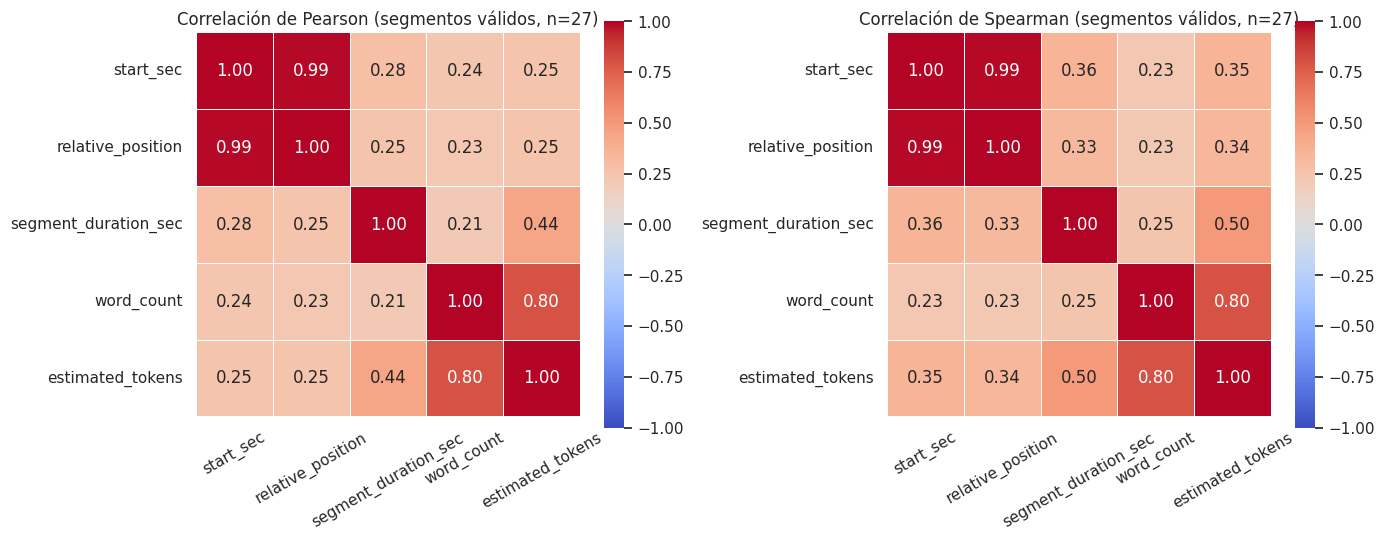

Unidad: segmento válido (n = 27), anidado en 5 sesiones -> observaciones no independientes; los p-values son orientativos y optimistas.
Correlaciones de Spearman por par (segmentos):


,variable_1,variable_2,n,spearman,p_asintotico
0,start_sec,relative_position,27,0.99,0.000
9,word_count,estimated_tokens,27,0.80,0.000
8,segment_duration_sec,estimated_tokens,27,0.50,0.009
1,start_sec,segment_duration_sec,27,0.36,0.068
3,start_sec,estimated_tokens,27,0.35,0.072
6,relative_position,estimated_tokens,27,0.34,0.081
4,relative_position,segment_duration_sec,27,0.33,0.095
7,segment_duration_sec,word_count,27,0.25,0.217
5,relative_position,word_count,27,0.23,0.258
2,start_sec,word_count,27,0.23,0.254


word_count vs estimated_tokens: rho = 0.80 -> alta correlación: los tokens se estiman a partir de la longitud del mismo texto.


In [26]:
seg_num = segments_clean.merge(sessions[["session_id", "duration_min"]], on="session_id")
# Posición relativa en la sesión (0 = inicio, 1 = final): permite comparar sesiones de distinta duración.
seg_num["relative_position"] = seg_num["start_sec"] / (seg_num["duration_min"] * 60)

seg_cols = ["start_sec", "relative_position", "segment_duration_sec", "word_count", "estimated_tokens"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(seg_num[seg_cols].corr(method=method), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
    ax.set_title(f"Correlación de {method.capitalize()} (segmentos válidos, n={len(seg_num)})")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print(f"Unidad: segmento válido (n = {len(seg_num)}), anidado en {seg_num['session_id'].nunique()} sesiones -> observaciones no independientes; los p-values son orientativos y optimistas.")
print("Correlaciones de Spearman por par (segmentos):")
corr_seg = corr_table(seg_num, seg_cols, "spearman")
display(corr_seg.sort_values("spearman", key=abs, ascending=False))

r_tw = spearmanr(seg_num["word_count"], seg_num["estimated_tokens"])[0]
print(f"word_count vs estimated_tokens: rho = {r_tw:.2f} -> alta correlación: los tokens se estiman a partir de la longitud del mismo texto.")

### 6.3 Asociación entre variables categóricas y relación numérica–categórica

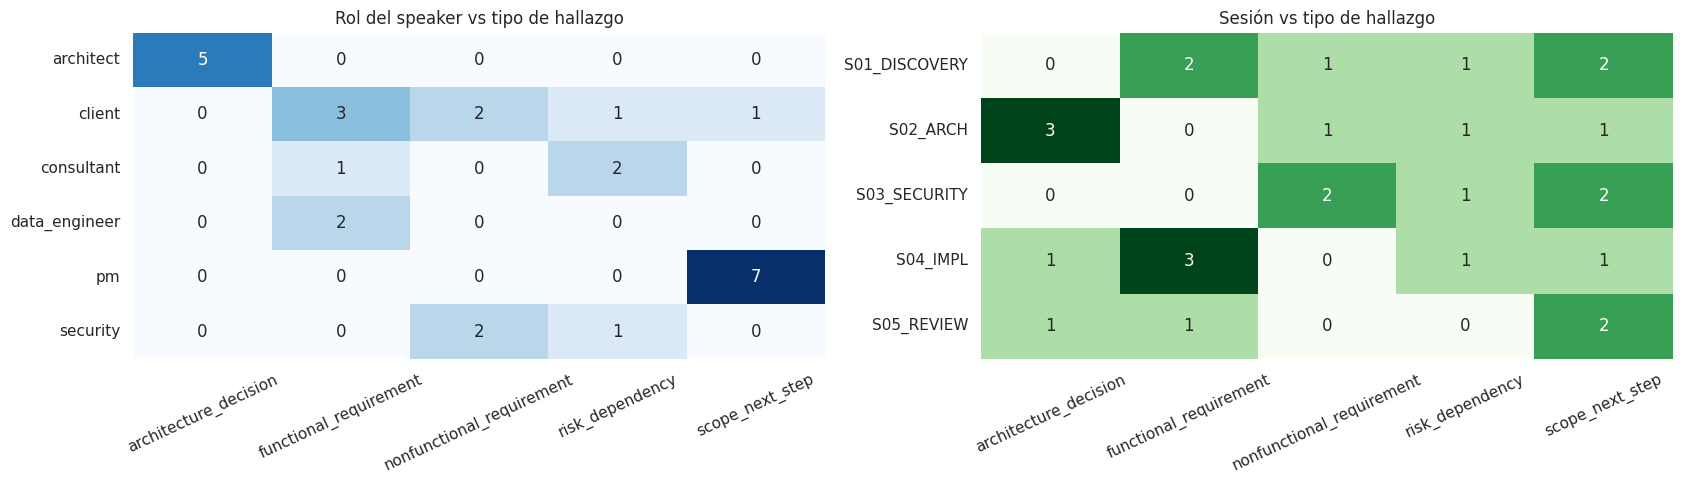

V de Cramér  speaker_role x expected_category : 0.78
V de Cramér  session_id   x expected_category : 0.39
Referencia: 0 = sin asociación, 1 = asociación perfecta. Con celdas de 0-3 casos es solo descriptivo (no se interpreta el p-value).


In [27]:
def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    return float(np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))))


ct_role = pd.crosstab(seg_num["speaker_role"], seg_num["expected_category"])
ct_sess = pd.crosstab(seg_num["session_id"], seg_num["expected_category"])

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.heatmap(ct_role, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Rol del speaker vs tipo de hallazgo")
sns.heatmap(ct_sess, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1])
axes[1].set_title("Sesión vs tipo de hallazgo")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

v_role, v_sess = cramers_v(ct_role), cramers_v(ct_sess)
print(f"V de Cramér  speaker_role x expected_category : {v_role:.2f}")
print(f"V de Cramér  session_id   x expected_category : {v_sess:.2f}")
print("Referencia: 0 = sin asociación, 1 = asociación perfecta. Con celdas de 0-3 casos es solo descriptivo (no se interpreta el p-value).")

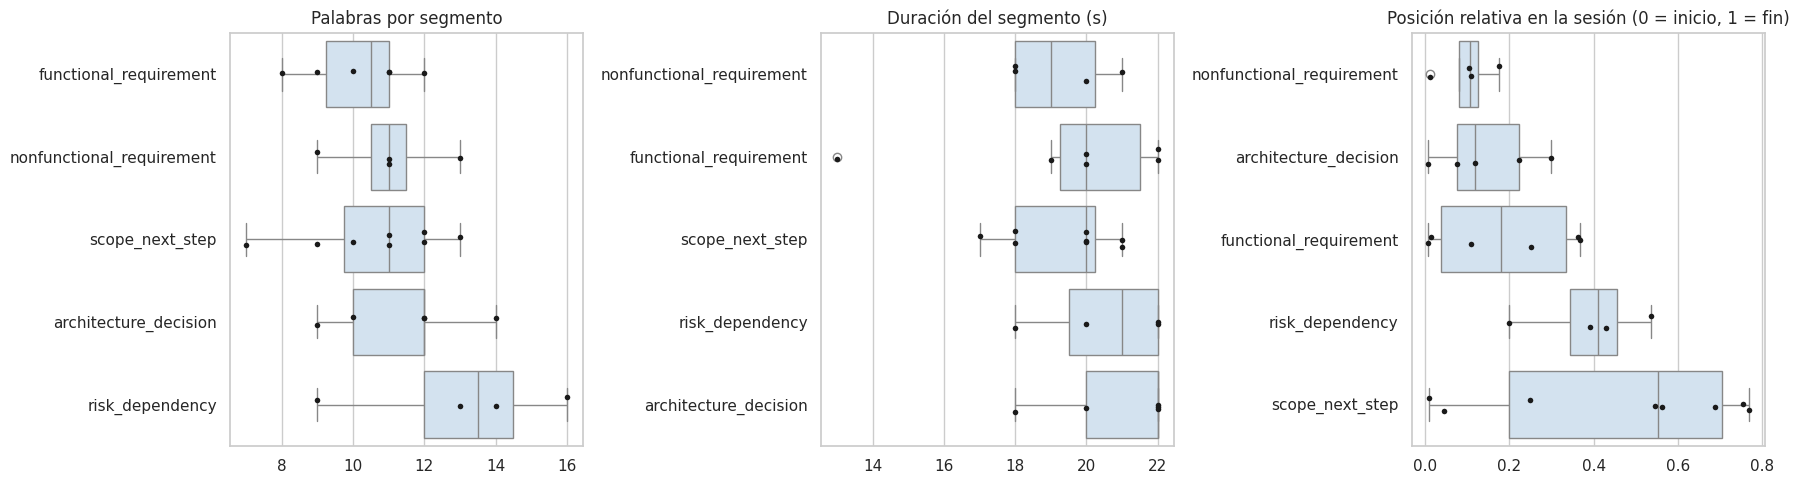

Kruskal-Wallis (¿difiere la variable entre tipos de hallazgo?). Unidad: segmento válido; epsilon2 = H/(n-1) es el tamaño del efecto:


,variable,grupos,n_total,n_por_grupo,H,p_value,epsilon2
0,word_count,5,27,4–8,4.11,0.391,0.16
1,segment_duration_sec,5,27,4–8,3.53,0.473,0.14
2,relative_position,5,27,4–8,8.14,0.086,0.31


p > 0,05 NO demuestra que los tipos sean iguales: con 4-8 segmentos por grupo la prueba tiene poca potencia, y los segmentos están agrupados por sesión (no independientes).
Posición relativa media por tipo de hallazgo:


,count,mean,min,max
expected_category,,,,
nonfunctional_requirement,4,0.10,0.01,0.18
architecture_decision,5,0.15,0.01,0.30
functional_requirement,6,0.19,0.01,0.37
risk_dependency,4,0.39,0.20,0.54
scope_next_step,8,0.45,0.01,0.77


Último segmento muestreado de cada sesión:


,session_id,segment_id,expected_category,relative_position
0,S05_REVIEW,SEG029,scope_next_step,0.54
1,S01_DISCOVERY,SEG006,scope_next_step,0.56
2,S03_SECURITY,SEG018,scope_next_step,0.76
3,S02_ARCH,SEG012,scope_next_step,0.69
4,S04_IMPL,SEG024,scope_next_step,0.77


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, titulo in zip(axes, ["word_count", "segment_duration_sec", "relative_position"],
                           ["Palabras por segmento", "Duración del segmento (s)", "Posición relativa en la sesión (0 = inicio, 1 = fin)"]):
    order_cat = seg_num.groupby("expected_category")[col].median().sort_values().index
    sns.boxplot(data=seg_num, y="expected_category", x=col, order=order_cat, color="#cfe2f3", ax=ax)
    sns.stripplot(data=seg_num, y="expected_category", x=col, order=order_cat, color="k", size=4, ax=ax)
    ax.set(title=titulo, xlabel="", ylabel="")
plt.tight_layout()
plt.show()

kw_rows = []
n_total = len(seg_num)
for col in ["word_count", "segment_duration_sec", "relative_position"]:
    grupos = [g[col].to_numpy() for _, g in seg_num.groupby("expected_category")]
    h, p = kruskal(*grupos)
    kw_rows.append([col, len(grupos), n_total, f"{min(len(g) for g in grupos)}–{max(len(g) for g in grupos)}",
                    round(float(h), 2), round(float(p), 3), round(float(h) / (n_total - 1), 2)])
print("Kruskal-Wallis (¿difiere la variable entre tipos de hallazgo?). Unidad: segmento válido; epsilon2 = H/(n-1) es el tamaño del efecto:")
display(pd.DataFrame(kw_rows, columns=["variable", "grupos", "n_total", "n_por_grupo", "H", "p_value", "epsilon2"]))
print("p > 0,05 NO demuestra que los tipos sean iguales: con 4-8 segmentos por grupo la prueba tiene poca potencia, "
      "y los segmentos están agrupados por sesión (no independientes).")

print("Posición relativa media por tipo de hallazgo:")
display(seg_num.groupby("expected_category")["relative_position"].agg(["count", "mean", "min", "max"]).round(2).sort_values("mean"))

print("Último segmento muestreado de cada sesión:")
display(seg_num.sort_values("start_sec").groupby("session_id").tail(1)[["session_id", "segment_id", "expected_category", "relative_position"]].round(2).reset_index(drop=True))

**Lectura.**
- **Rol y tipo de hallazgo (V de Cramér = 0,78, asociación fuerte):** el arquitecto solo aparece en decisiones de arquitectura (5 de 5) y el PM casi solo en alcance y siguientes pasos (7 de los 8 segmentos de ese tipo; el restante es del cliente). Es esperable, pero **es un artefacto del diseño sintético** y no puede generalizarse.
- **Tendencia temporal:** requisitos no funcionales, decisiones de arquitectura y requisitos funcionales aparecen pronto (posición relativa media 0,10–0,19), mientras que riesgos y siguientes pasos aparecen más tarde (0,39 y 0,45). En las cinco sesiones con transcripción el último segmento muestreado es un `scope_next_step`. La diferencia de posición entre tipos **no alcanza significancia al 5 %** (Kruskal-Wallis p = 0,086), pero el tamaño del efecto no es despreciable (ε² ≈ 0,31): con 4 a 8 segmentos por grupo la prueba tiene poca potencia, así que el resultado **no demuestra que los tipos sean iguales**, solo que esta muestra no basta para confirmarlo. Para longitud (p = 0,39) y duración del segmento (p = 0,47) tampoco se detecta diferencia, con la misma salvedad. Es una tendencia descriptiva coherente con una reunión real (se abre con requisitos y se cierra con acuerdos), pero los segmentos están agrupados por sesión y el corpus fue diseñado a mano.

### 6.4 Balance de clases y distribución por partición

Segmentos válidos por categoría (razón mayor/menor = 2.0):


,segmentos
expected_category,
scope_next_step,8
functional_requirement,6
architecture_decision,5
nonfunctional_requirement,4
risk_dependency,4


Preguntas del gold por categoría (razón mayor/menor = 1.0):


,preguntas
category,
Requisitos funcionales,6
Requisitos no funcionales e infraestructura,6
Decisiones de arquitectura,6
Riesgos y dependencias,6
"Alcance, responsables y siguientes pasos",6


,sesiones,segmentos_validos,preguntas_gold
development,4,23,28
validation,1,4,2
test,1,0,0


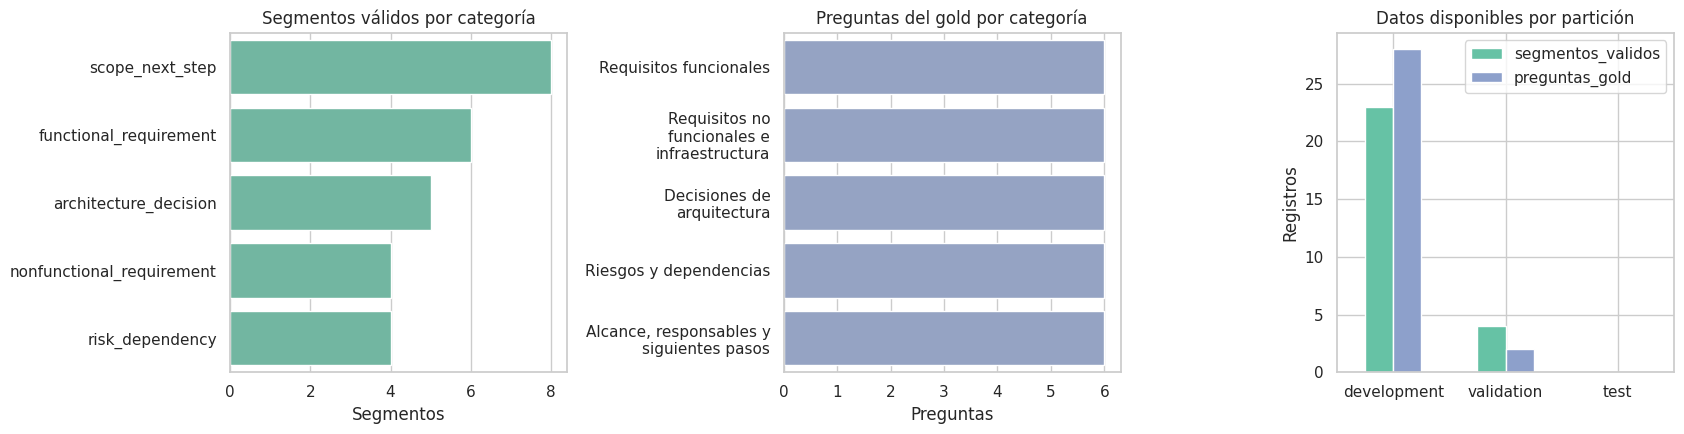

In [29]:
def imbalance(counts):
    return round(counts.max() / counts.min(), 2)


cnt_seg = segments_clean["expected_category"].value_counts()
cnt_gold = gold["category"].value_counts()
print(f"Segmentos válidos por categoría (razón mayor/menor = {imbalance(cnt_seg)}):")
display(cnt_seg.rename("segmentos").to_frame())
print(f"Preguntas del gold por categoría (razón mayor/menor = {imbalance(cnt_gold)}):")
display(cnt_gold.rename("preguntas").to_frame())

# Distribución por partición (desarrollo / validación / prueba)
split_map = sessions.set_index("session_id")["dataset_split"]
seg_split = segments_clean["session_id"].map(split_map).value_counts().reindex(["development", "validation", "test"]).fillna(0).astype(int)
gold_split = gold["session_id"].map(split_map).value_counts().reindex(["development", "validation", "test"]).fillna(0).astype(int)
split_tbl = pd.DataFrame({"sesiones": sessions["dataset_split"].value_counts().reindex(["development", "validation", "test"]),
                          "segmentos_validos": seg_split, "preguntas_gold": gold_split})
display(split_tbl)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.barplot(x=cnt_seg.values, y=cnt_seg.index, color="#66c2a5", ax=axes[0])
axes[0].set(title="Segmentos válidos por categoría", xlabel="Segmentos", ylabel="")
sns.barplot(x=cnt_gold.values, y=[textwrap.fill(i, 24) for i in cnt_gold.index], color="#8da0cb", ax=axes[1])
axes[1].set(title="Preguntas del gold por categoría", xlabel="Preguntas", ylabel="")
split_tbl[["segmentos_validos", "preguntas_gold"]].plot.bar(ax=axes[2], rot=0, color=["#66c2a5", "#8da0cb"])
axes[2].set(title="Datos disponibles por partición", xlabel="", ylabel="Registros")
plt.tight_layout()
plt.show()

**Lectura.** Las **categorías están balanceadas** en el gold (6 preguntas por categoría, razón 1,0) y con un desequilibrio leve en los segmentos válidos (8 de `scope_next_step` frente a 4 de las categorías menores, razón 2,0). El **desequilibrio real está en las particiones y en las sesiones**: 23 de 27 segmentos y 28 de 30 preguntas están en `development`; `validation` tiene 4 segmentos y 2 preguntas; y `test` no tiene ninguno (S06 no tiene transcripción). Además las preguntas se reparten de forma desigual entre sesiones (9 en S02 frente a 2 en S05). Antes de evaluar habrá que completar S06 o redefinir las particiones.

## 7. Selección de características y reducción de dimensionalidad

Se decide qué información conserva valor semántico, cuál se necesita solo como evidencia o control y cuál es ruido o redundancia. **No se aplica PCA**: el problema no es entrenar un modelo tabular con muchas variables numéricas, y el input principal es texto. La reducción se logra **no enviando al contexto del modelo** información redundante, de formato o personal, y conservando aparte los metadatos de auditoría. La correlación de la sección 6 sustenta la eliminación de `estimated_tokens` como característica.

In [30]:
feature_selection = pd.DataFrame([
    ["text_clean", "Entrada del modelo", "Conservar", "Contiene el significado de la conversación."],
    ["speaker_role", "Entrada / contexto", "Conservar", f"Aporta contexto sin nombres propios; asociado al tipo de hallazgo (V de Cramér = {v_role:.2f})."],
    ["start_sec / end_sec", "Evidencia", "Conservar", "Permiten rastrear un hallazgo a su intervalo en la sesión."],
    ["session_id / segment_id", "Trazabilidad", "Conservar", "Identificadores únicos, no variables predictoras."],
    ["has_visual_reference", "Control experimental", "Conservar", "Permitirá evaluar cuándo el video aporta información adicional."],
    ["expected_category", "Etiqueta de referencia", "Conservar solo para evaluación", "Es la etiqueta del corpus sintético; no debe entrar como input del modelo (fuga de información)."],
    ["speaker_clean", "Trazabilidad", "Conservar fuera del contexto", "7 nombres propios: redundante con speaker_role y potencial dato personal en datos reales."],
    ["duration_min / num_speakers", "Metadata de sesión", "Conservar fuera del texto", "Caracterizan volumen y necesidades de segmentación."],
    ["dataset_split", "Metadata de sesión", "Conservar fuera del texto", "Necesario para evaluar sin contaminar particiones."],
    ["video_format", "Metadata de sesión", "Conservar fuera del texto", "Útil para ingestión; no aporta semántica al TDD."],
    ["word_count", "Descriptiva", "Conservar como metadato", "Resume el volumen de contexto por segmento."],
    ["estimated_tokens", "Descriptiva", "Eliminar del segmento", f"Redundante con word_count (rho = {r_tw:.2f}); se usa solo agregada por sesión."],
    ["segment_duration_sec", "Derivada", "Eliminar del segmento", "Se obtiene de end_sec − start_sec."],
    ["has_audio", "Constante", "Eliminar", "Vale True en todas las sesiones: varianza cero, sin información."],
    ["text_raw", "Original", "Conservar solo en origen", "Se mantiene en data/ para auditoría; el modelo usa text_clean."],
    ["etiquetas HTML", "Ruido", "Eliminar del texto", "Elementos de formato sin información del negocio."],
    ["duplicados", "Ruido", "Eliminar", "Repiten evidencia y consumen contexto innecesario."],
    ["text_for_duplicate_check, banderas q_*", "Auxiliares", "Eliminar del conjunto final", "Solo sirven para el diagnóstico de calidad; quedan en quality_report."],
], columns=["caracteristica", "uso", "decision", "justificacion"])
display(feature_selection)

FINAL_COLS = ["session_id", "segment_id", "start_sec", "end_sec", "speaker_clean", "speaker_role",
              "has_visual_reference", "text_clean", "word_count", "expected_category", "category_es"]
segments_final = segments_clean[FINAL_COLS].reset_index(drop=True)

print(f"segments: {int(resumen.loc['segments', 'columnas'])} columnas originales -> {segments_final.shape[1]} en el conjunto final "
      f"(sin banderas de calidad, columnas auxiliares ni derivadas redundantes).")
print("Entran como contexto semántico al modelo solo 2 columnas: ['text_clean', 'speaker_role']; "
      "el resto son metadatos de trazabilidad/control o etiquetas de referencia para evaluar.")
display(segments_final.head())

,caracteristica,uso,decision,justificacion
0,text_clean,Entrada del modelo,Conservar,Contiene el significado de la conversación.
1,speaker_role,Entrada / contexto,Conservar,Aporta contexto sin nombres propios; asociado al tipo de hallazgo ...
2,start_sec / end_sec,Evidencia,Conservar,Permiten rastrear un hallazgo a su intervalo en la sesión.
3,session_id / segment_id,Trazabilidad,Conservar,"Identificadores únicos, no variables predictoras."
4,has_visual_reference,Control experimental,Conservar,Permitirá evaluar cuándo el video aporta información adicional.
5,expected_category,Etiqueta de referencia,Conservar solo para evaluación,Es la etiqueta del corpus sintético; no debe entrar como input del...
6,speaker_clean,Trazabilidad,Conservar fuera del contexto,7 nombres propios: redundante con speaker_role y potencial dato pe...
7,duration_min / num_speakers,Metadata de sesión,Conservar fuera del texto,Caracterizan volumen y necesidades de segmentación.
8,dataset_split,Metadata de sesión,Conservar fuera del texto,Necesario para evaluar sin contaminar particiones.
9,video_format,Metadata de sesión,Conservar fuera del texto,Útil para ingestión; no aporta semántica al TDD.


segments: 9 columnas originales -> 11 en el conjunto final (sin banderas de calidad, columnas auxiliares ni derivadas redundantes).
Entran como contexto semántico al modelo solo 2 columnas: ['text_clean', 'speaker_role']; el resto son metadatos de trazabilidad/control o etiquetas de referencia para evaluar.


,session_id,segment_id,start_sec,end_sec,speaker_clean,speaker_role,has_visual_reference,text_clean,word_count,expected_category,category_es
0,S01_DISCOVERY,SEG001,15,28,Laura_Client,client,False,Necesitamos que el portal permita consultar el estado de cada soli...,11,functional_requirement,Requisitos funcionales
1,S01_DISCOVERY,SEG002,95,112,Ana_PM,pm,False,El alcance inicial cubrirá únicamente usuarios internos.,7,scope_next_step,"Alcance, responsables y siguientes pasos"
2,S01_DISCOVERY,SEG003,220,238,Carlos_Client,client,False,La solución debe responder en menos de tres segundos para las cons...,13,nonfunctional_requirement,Requisitos no funcionales e infraestructura
3,S01_DISCOVERY,SEG004,420,438,Miguel_Consultant,consultant,False,Existe dependencia con la definición del catálogo de usuarios.,9,risk_dependency,Riesgos y dependencias
4,S01_DISCOVERY,SEG005,760,780,UNKNOWN,client,False,El cliente también requiere descargar el resultado en PDF.,9,functional_requirement,Requisitos funcionales


## 8. Evaluación del sistema: estado y pendientes

Este EDA **no acredita el desempeño de Cloud Copilot ni de ningún modelo**: no existe en este notebook una prueba funcional (entrada, evidencia utilizada, salida real y comparación con la referencia). Lo que sí se deja explícito es qué falta, para acordarlo con responsables y fechas.

Estado actual de las particiones (de la sección 6.4): `test` no tiene segmentos ni preguntas porque S06 no tiene transcripción, y `validation` tiene solo 4 segmentos y 2 preguntas.

In [31]:
pendientes = pd.DataFrame([
    ["Partición test vacía", "S06 no tiene transcripción; 0 segmentos y 0 preguntas en test", "Transcribir S06 o redefinir las particiones", "L4"],
    ["Preguntas concretas", "Las 30 preguntas son plantillas ('Pregunta sintética N sobre ...')", "Redactar preguntas reales, con casos difíciles, y revisarlas", "L4"],
    ["Revisión humana del gold", "28 con reviewer asignado en el CSV; Q008 y Q024 pendientes; no hay fecha ni criterio", "Registro de quién revisó, cuándo y con qué criterio", "L1"],
    ["Prueba funcional de Cloud Copilot", "No existe en este notebook", "Un caso completo: entrada, evidencia, salida real y comparación con la referencia (precisión, completitud, respaldo de afirmaciones)", "—"],
    ["Juez LLM (si se usa)", "No definido", "Rúbrica del juez y contraste con revisión humana", "—"],
    ["Relaciones semánticas consulta–fragmento", "No existe; el mapa de correlación entre metadatos no la acredita", "Matriz de similitud o relevancia consulta–fragmento con ejemplos correctos y fallidos y su revisión (requiere consultas reales)", "L5"],
    ["Presupuesto de contexto", "Solo hay una estimación caracteres/4 (no es el tokenizador del modelo)", "Tokens con el tokenizador del modelo + instrucciones + evidencia + salida", "L2"],
    ["Idiomas y ruido", "Corpus en español con términos técnicos en inglés (p. ej. RAG, JSON); solo hay un caso de markup en segmentos y uno en el gold", "Identificación de idiomas y pruebas de limpieza con transcripciones reales (p. ej. WebVTT)", "L3"],
    ["Componente temporal", "Cobertura temporal única 5,0–5,6 %; texto útil 4,4–5,6 % (muestreo disperso)", "Justificar el muestreo o ampliarlo según la evolución de temas dentro de la sesión", "L6"],
], columns=["pendiente", "estado actual", "qué se necesita", "criterio L"])
pendientes["responsable"] = "por acordar"
pendientes["fecha"] = "por acordar"
with pd.option_context("display.max_colwidth", None, "display.width", 300):
    display(pendientes)
pendientes.to_csv(OUTPUT / "pendientes_evaluacion.csv", index=False)

,pendiente,estado actual,qué se necesita,criterio L,responsable,fecha
0,Partición test vacía,S06 no tiene transcripción; 0 segmentos y 0 preguntas en test,Transcribir S06 o redefinir las particiones,L4,por acordar,por acordar
1,Preguntas concretas,Las 30 preguntas son plantillas ('Pregunta sintética N sobre ...'),"Redactar preguntas reales, con casos difíciles, y revisarlas",L4,por acordar,por acordar
2,Revisión humana del gold,28 con reviewer asignado en el CSV; Q008 y Q024 pendientes; no hay fecha ni criterio,"Registro de quién revisó, cuándo y con qué criterio",L1,por acordar,por acordar
3,Prueba funcional de Cloud Copilot,No existe en este notebook,"Un caso completo: entrada, evidencia, salida real y comparación con la referencia (precisión, completitud, respaldo de afirmaciones)",—,por acordar,por acordar
4,Juez LLM (si se usa),No definido,Rúbrica del juez y contraste con revisión humana,—,por acordar,por acordar
5,Relaciones semánticas consulta–fragmento,No existe; el mapa de correlación entre metadatos no la acredita,Matriz de similitud o relevancia consulta–fragmento con ejemplos correctos y fallidos y su revisión (requiere consultas reales),L5,por acordar,por acordar
6,Presupuesto de contexto,Solo hay una estimación caracteres/4 (no es el tokenizador del modelo),Tokens con el tokenizador del modelo + instrucciones + evidencia + salida,L2,por acordar,por acordar
7,Idiomas y ruido,"Corpus en español con términos técnicos en inglés (p. ej. RAG, JSON); solo hay un caso de markup en segmentos y uno en el gold",Identificación de idiomas y pruebas de limpieza con transcripciones reales (p. ej. WebVTT),L3,por acordar,por acordar
8,Componente temporal,"Cobertura temporal única 5,0–5,6 %; texto útil 4,4–5,6 % (muestreo disperso)",Justificar el muestreo o ampliarlo según la evolución de temas dentro de la sesión,L6,por acordar,por acordar


## 9. Exportación de resultados

Solo se exportan resultados derivados; los archivos de entrada permanecen intactos en `data/`.

In [32]:
assert QUALITY_OK, "No se exporta: fallaron las pruebas de calidad (secciones 5.1b y 5.3b)."

segments_final.to_csv(OUTPUT / "transcript_segments_clean.csv", index=False)
segments_excluded.to_csv(OUTPUT / "transcript_segments_excluded.csv", index=False)
sessions_clean.to_csv(OUTPUT / "sessions_clean.csv", index=False)
gold_clean.drop(columns=["q_missing_answer", "q_missing_evidence", "q_missing_reviewer", "q_html_markup"]).to_csv(OUTPUT / "gold_clean.csv", index=False)
rag_clean.drop(columns=["q_empty", "q_duplicate"]).to_csv(OUTPUT / "rag_documents_clean.csv", index=False)
session_summary.to_csv(OUTPUT / "session_summary.csv", index=False)
quality_report.to_csv(OUTPUT / "quality_report.csv", index=False)
preprocessing_decisions.to_csv(OUTPUT / "preprocessing_decisions.csv", index=False)
feature_selection.to_csv(OUTPUT / "feature_selection.csv", index=False)
cardinality.to_csv(OUTPUT / "cardinality.csv", index=False)

print("Archivos generados en output/:")
for path in sorted(OUTPUT.glob("*.csv")):
    print("-", path.name)

Archivos generados en output/:
- cardinality.csv
- feature_selection.csv
- gold_clean.csv
- pendientes_evaluacion.csv
- preprocessing_decisions.csv
- quality_report.csv
- rag_documents_clean.csv
- session_summary.csv
- sessions_clean.csv
- transcript_segments_clean.csv
- transcript_segments_excluded.csv


# 10. Conclusiones

Resumen del EDA sobre el corpus piloto (6 sesiones, 30 segmentos, 30 preguntas de evaluación y 6 documentos RAG), organizado según las preguntas propuestas en la actividad.

**1. ¿Hay valores faltantes? ¿Hay patrones de ausencia?** Sí, pero pocos y puntuales: 1 speaker (SEG005, S01), 1 texto (SEG028, S05), 2 revisores en el gold (Q008 y Q024, **ambos de S02**) y una sesión sin transcripción (S06, partición `test`). El `duplicate_of` vacío en 5 de 6 documentos RAG es un faltante estructural, no un error. Los faltantes de `segments` no coinciden en el mismo registro; los dos del gold sí se concentran en S02 (posible revisión incompleta, aunque con n = 2 no es concluyente). *Tratamiento:* speaker → `UNKNOWN` (se conserva); texto faltante → excluido y guardado aparte; sesión sin transcripción → marcada `usable_for_text = False`, sin imputar; revisores faltantes → `pending_review`.

**2. ¿Cuáles son las estadísticas resumidas?** Las sesiones duran 30–40 min (media 34,8; desviación 3,7) con 3–4 participantes. Los segmentos duran ≈ 13–22 s y tienen 7–16 palabras (media ≈ 11), es decir, son frases cortas. Los documentos RAG tienen 900–3 200 palabras (el vacío tiene 0). Las categóricas dominantes son MP4 (4 de 6 sesiones) y el rol `pm` (7 segmentos válidos de tipo siguiente paso).

**3. ¿Hay valores atípicos?** En las **sesiones, ninguno** (ni por IQR ni fuera del rango esperado de 30–45 min). En los **segmentos**, el único valor realmente anómalo era SEG017 (duración de −5 s, fin menor que inicio): una inconsistencia lógica que se excluyó. Un ejercicio de sensibilidad con una sesión hipotética de 150 min (sobre una copia, sin tocar los datos) confirma que el criterio la marcaría. Tras depurar solo queda SEG011 en `word_count` (16 palabras, apenas sobre el límite IQR de 15,8): contenido legítimo que se conserva.

**4. ¿Cuál es la cardinalidad de las categóricas?** Baja: como máximo 7 clases (`speaker`; 6 roles, 5 tipos de hallazgo, 3 formatos de documento). **No hay alta cardinalidad**, así que no se agrupan categorías ni se codifica. `segment_id`, `question_id` y `evidence_reference` son identificadores de trazabilidad, no variables explicativas. `project_phase` y `document_type` son únicas por fila solo por el tamaño de la muestra (n = 6) y deberán revisarse con datos reales. `has_audio` es constante y se descarta.

**5. ¿Hay distribuciones sesgadas? ¿Hace falta una transformación no lineal?** `word_count`, `estimated_tokens` y `start_sec` son aproximadamente simétricas (|asimetría| < 1). `segment_duration_sec` tiene un sesgo moderado a la izquierda (−1,31) causado por unos pocos segmentos cortos y por tratarse de una variable derivada de los timestamps. **No se aplica ninguna transformación:** el log corrige sesgos a la derecha, la variable se elimina del conjunto final y el texto lo procesa un LLM.

**6. ¿Se identifican tendencias temporales?** Sí, descriptivas. Los segmentos son un **muestreo disperso**: la cobertura temporal única es de 5,0–5,6 % de cada sesión y la de texto útil de 4,4–5,6 % (en S05, 121 s brutos → 101 s sin la copia → 80 s sin el segmento sin texto, 4,4 %). Requisitos y decisiones de arquitectura aparecen pronto (posición relativa media 0,10–0,19); riesgos y siguientes pasos más tarde (0,39 y 0,45), y en las cinco sesiones el último segmento muestreado es un siguiente paso. La diferencia no alcanza significancia al 5 % (Kruskal-Wallis, p = 0,086; 4 a 8 segmentos por grupo, anidados en 5 sesiones), pero tampoco demuestra que los tipos sean iguales: la prueba tiene poca potencia y el efecto no es despreciable (ε² ≈ 0,31). Refleja en parte cómo se diseñó la muestra.

**7. ¿Hay correlación entre las variables?** *A nivel sesión (n = 5)*, la duración se relaciona fuertemente con el volumen de texto (Spearman = 1,00, p exacto ≈ 0,017; Pearson ≈ 0,94); los demás coeficientes no son significativos con la prueba exacta (el p asintótico de `scipy` no es confiable con n = 5). Además depende del número de segmentos que se eligieron (rho = 0,89 con la duración), así que es una señal operativa del contexto a procesar y no una propiedad de las reuniones. *A nivel segmento (n = 27, anidados en 5 sesiones, por lo que los p-values son orientativos)*, solo `word_count` y `estimated_tokens` están claramente correlacionadas (rho = 0,80), lo que justifica eliminar los tokens como característica; las demás son débiles o moderadas (la mayor, duración del segmento–tokens, rho = 0,50), salvo `start_sec`–posición relativa (0,99), que es mecánica. *Entre categóricas*, `speaker_role` y `expected_category` están fuertemente asociadas (V de Cramér = 0,78: arquitecto → decisiones, PM → siguientes pasos), pero es un artefacto del diseño sintético; la asociación con la sesión es moderada (0,39).

**8. ¿Cómo se distribuyen los datos por categorías (bivariado)?** No se detecta diferencia entre tipos de hallazgo en la longitud (p = 0,39) ni en la duración del segmento (p = 0,47); con grupos de 4 a 8 segmentos eso no demuestra que sean iguales. Lo que sí varía es la posición temporal (punto 6) y quién habla (punto 7).

**9. ¿Se deberían normalizar las imágenes?** No aplica en este avance: no se extraen frames del video. Si la implementación posterior los usa, habrá que revisar resolución, formato (MP4/WEBM) y frecuencia de muestreo según el modelo multimodal elegido.

**10. ¿Hay desequilibrio de clases?** Las **categorías están balanceadas**: 6 preguntas por categoría en el gold (razón 1,0) y un desequilibrio leve en los segmentos válidos (8 `scope_next_step` frente a 4–6 en las demás; razón 2,0). El **desequilibrio importante es el de las particiones**: 23 de 27 segmentos y 28 de 30 preguntas están en `development`, `validation` tiene 4 segmentos y 2 preguntas, y **`test` está vacío** porque S06 no tiene transcripción. Además las preguntas se reparten de forma desigual entre sesiones (9 en S02 frente a 2 en S05).

**Resultado del preprocesamiento.** De 30 segmentos quedan **27 válidos** (3 excluidos, 10 %): texto faltante, timestamp inválido y una copia duplicada (se conserva la primera). Se limpió el markup HTML (en `segments` y en la respuesta esperada de Q014 del gold), se marcó 1 speaker como `UNKNOWN`, se unificaron las etiquetas de categoría entre `segments` (inglés) y `gold` (español) y se verificó por código (secciones 5.1b y 5.3b, con una prueba negativa que muestra qué pasa cuando una validación falla) que **las 30 preguntas del gold tienen evidencia disponible** con sesión, intervalo y texto idénticos al segmento fuente. Esto comprueba trazabilidad, no calidad semántica. Solo **4 de 6** documentos RAG son elegibles para indexar (8 100 palabras): se descartan el vacío y la copia. La reducción de dimensionalidad se logró seleccionando características (sección 7): al modelo solo entran `text_clean` y `speaker_role`; el resto es trazabilidad, control o metadatos.

**Hallazgos clave para el proyecto**
- La partición `test` está vacía: hay que obtener o generar la transcripción de S06 antes de evaluar.
- Las 30 preguntas del gold son plantillas genéricas; 28 tienen un reviewer asignado en el CSV (sin fecha ni criterio que lo acredite) y 2 (Q008 y Q024, ambas de S02) siguen pendientes. La respuesta de Q014 traía markup HTML heredado de su segmento.
- Este EDA **no acredita el desempeño del asistente**: faltan la prueba funcional, el juez (si se usa), la matriz de similitud consulta–fragmento y el presupuesto de contexto (sección 8).
- La corrección de duplicados debe conservar una copia: descartar ambas elimina el contenido.
- Los archivos de entrada usan **codificaciones distintas** (cp1252 en `transcript_segments_raw.csv`, UTF-8 en los demás); una lectura con una sola codificación corrompe los acentos.

**Limitaciones.** La muestra es pequeña y sintética (n = 6 sesiones, 27 segmentos válidos): los coeficientes y p-values son descriptivos y no permiten generalizar a reuniones reales; además los segmentos están agrupados por sesión (no independientes) y un resultado no significativo no demuestra ausencia de diferencias. Las asociaciones entre rol y tipo de hallazgo y la posición temporal reflejan en parte el diseño manual del corpus. Al sustituir estos archivos por sesiones reales o desensibilizadas habrá que repetir el análisis de cardinalidad, atípicos y correlaciones, manteniendo la misma lógica de carga, validación, limpieza y trazabilidad.